<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/01_Network_Intrusion_Detection/CNNQNN_IntrusionDetection_BN2025.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Improved CNN-based quantum neural network for intrusion detection, plus Blowfish: Nithya B. N. et al. (2025) step by step

This notebook re-implements, runs and checks the method of

> Nithya B. N., Sailaja Bhaskar Murthy and Samudyatha D. S., "Improved Quantum Neural Network for Intrusion Detection and
> Blowfish for Data Security", *2025 Control Instrumentation System Conference (CISCON)*, IEEE, 2025.
> DOI 10.1109/CISCON66933.2025.11337273

The paper (4 pages, no code) proposes a two-stage network-security pipeline. Stage 1 is an intrusion detector, an
**"improved CNN-based quantum neural network (QNN)"**: a small 1-D convolutional network (Conv1D, batch normalisation, tanh,
leaky ReLU, scaled dot-product, average pooling and a new *W-HHSM-BN* layer) whose output feeds a variational quantum
circuit. Stage 2: if the traffic is judged clean, the data are protected with the **Blowfish** cipher. The detector is
compared with Bi-GRU, AlexNet, DenseNet, GhostNet and a plain QNN on the KDD Cup 1999 data.

**What the notebook does.** It downloads the 10 % KDD Cup 99 file, removes duplicates, draws a class-balanced sample, fits
every transform on the training split only, and trains the six detectors of the paper (all in PyTorch; the two quantum
ones with a PennyLane circuit) for several training-data ratios (TD = 60, 75, 90 %). It then computes the paper's nine metrics
(specificity, sensitivity, accuracy, precision, F-measure, MCC, NPV, FPR, FNR), redraws the paper's Figs. 3 to 5 and
Table I, and puts the paper's numbers next to ours with a verdict per claim. Blowfish is implemented from scratch in pure
Python (constants computed from the digits of pi, checked against the published test vectors) and applied to the records
the detector declares clean.

**How to run it.** Open in Colab (badge above), choose a CPU runtime and use *Runtime -> Run all*. The first cell installs
a pinned PennyLane; if Colab asks to restart the session, restart and run all again. No GPU, no quantum-cloud account and
no Hugging Face token are needed: the KDD Cup 99 file is public and ungated (a token, if you have one, is read only from
`HF_TOKEN` / Colab Secrets and only for the optional Hugging Face fallback).

**Runtime.** `FAST_MODE = True` (3,000 connections, one run, 2 quantum epochs) takes a few minutes. `FAST_MODE = False`
(6,000 connections, three TD ratios, three seeds at TD = 90 %, 6 quantum epochs, plus ablations) is the full run; it took 47 minutes on a shared, heavily loaded laptop CPU (2 threads) and the committed outputs come from it.

**What you get at the end.** All metrics of the six detectors and of Random Forest / SVM baselines, the redrawn Figs. 3 to 5
and Table I, a working Blowfish with test-vector proof and round-trip on real flow records, and a verdict table.

## The paper in one page

**Problem.** Decide for each network connection whether it is an attack or normal traffic; if it is normal, transmit it
encrypted.

**Decision.** Improved CNN-based QNN (detector) -> Blowfish (data security).

**Method (Sec. IV).** Input `D_t` -> Conv1D -> BatchNorm -> tanh -> Leaky ReLU -> scaled dot-product -> average pooling ->
**W-HHSM-BN** layer (Eqs. 1 to 3: a "weighted hard hyperbolic softmax response" followed by batch normalisation) -> dense ->
dropout -> flatten -> QNN (data encoded into qubit states, rotation gates with connecting gates, measurement decoded to the
output; trained with Adam).

**Blowfish (Sec. V).** 18 32-bit sub-keys (S-array) and four 256-entry 32-bit S-boxes, key expansion, 16-round Feistel
network with `F(x) = ((S1[a] + S2[b]) mod 2^32 XOR S3[c]) + S4[d] mod 2^32`.

**Data.** KDD Cup 1999 (Kaggle `galaxyh/kdd-cup-1999-data`).

**Claims.**

| Claim | Value in the paper |
|---|---|
| Accuracy at TD = 90 % (Fig. 3c) | improved CNN-QNN 0.97583; Bi-GRU 0.90694; AlexNet 0.91527; DenseNet 0.91528; GhostNet 0.92139; QNN 0.94833 |
| FPR at TD = 90 % (Fig. 5a) | 0.0143 (proposed) vs 0.05568, 0.050683, 0.050683, 0.047015, 0.030843 |
| MCC at TD = 90 % (Fig. 4b) | 0.9130 (proposed) vs 0.665223, 0.695203, 0.69520, 0.717188, 0.814124 |
| Table I accuracy statistics (min / mean / SD / median / max) | proposed 0.9399 / 0.9571 / 0.0135 / 0.9564 / 0.9758; QNN 0.9099 / 0.9297 / 0.0148 / 0.9302 / 0.9483; classical nets 0.857 to 0.921 |
| Ranking | improved CNN-QNN > QNN > GhostNet, DenseNet, AlexNet > Bi-GRU on all metrics |
| Table II | Blowfish has lower CCA / CPA / FIA / KPA "attack values" than RSA, AES and Fernet for key sizes 16 to 128 |

### What follows the paper and what had to be chosen

The paper is a short conference paper; the equations are partly illegible in the PDF text and many details are missing.
Every choice below is marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Data | "kdd-cup-1999-dataset" (Kaggle), no file named | the 10 % KDD Cup 99 file (494,021 connections) from `sklearn.datasets.fetch_kddcup99`, fallback UCI / Hugging Face mirrors |
| Cleaning | not stated | exact duplicates removed (145,586 unique connections remain) |
| Task | "attacked or not" (binary), analysis "on varied attack types" | binary: normal vs attack (attack = positive class); the original 23 labels / 5 families are kept for plots |
| Sample size and split | accuracies are multiples of 1/3600 (0.906944 = 3265/3600), TD = 90 % | **inferred** size 36,000 (test = 3,600 at TD = 90 %); **used here 6,000** connections (3,000 + 3,000, class balanced) to keep the quantum simulation fast (600 test connections at TD = 90 %); TD in {60, 75, 90} % |
| Preprocessing | not stated | one-hot encoding of protocol / service / flag, drop constant columns, MinMax to [0, 1]; all fitted on the training split only |
| Input of the CNN models | `D_t` | the ~115-column preprocessed vector as a 1-D sequence with one channel |
| Input of the plain QNN | `D_t` | PCA to 6 components (fitted on training) scaled to [0, pi]: one angle per qubit |
| Qubits / variational block | not stated | 6 qubits; RY angle encoding; 3 `StronglyEntanglingLayers` (54 parameters); read-out `<Z_0>`; logit `a <Z_0> + b` |
| Improved CNN | Conv1D, BN, tanh, Leaky ReLU, scaled dot, avg pool, W-HHSM-BN, dense, dropout, flatten | exactly this order; 8 filters (kernel 3), residual scaled dot-product self-attention over positions, AvgPool(2), W-HHSM-BN, flatten, dropout 0.2, dense to 6 values, `pi * sigmoid` (angles) |
| W-HHSM-BN (Eqs. 1 to 3) | equations garbled in the PDF text | **reconstruction** (see Section 4): hard-clipped softmax response, weighted softplus ratio with `w_max = 0.9`, `w_min = 0.4`, multiplied with the batch-normalised input |
| Comparators | Bi-GRU, AlexNet, DenseNet, GhostNet, QNN (architectures not given) | compact 1-D PyTorch versions of each (a few thousand parameters), same input as the proposed CNN |
| Optimiser | Adam | Adam; circuit weights lr 0.05, CNN weights of the hybrid lr 0.005, classical nets lr 0.003; batch 256 |
| Batch-norm statistics | not stated | after training, the running statistics of every BatchNorm layer are re-estimated on the whole training set (otherwise DenseNet / GhostNet sometimes collapse to one class at test time after so few Adam steps) |
| Epochs | not stated | 6 quantum, 8 classical (full run); 2 and 3 in `FAST_MODE` |
| Seeds | not stated | 42, 43, 44 at TD = 90 %; 42 for the other TD ratios |
| Table I statistics | min / mean / SD / median / max over unspecified scenarios | over all (TD, seed) runs of a model |
| Table II "attack values" | CCA, CPA, FIA, KPA of Blowfish / RSA / AES / Fernet for key sizes 16 to 128; no definition of the measure | **cannot be checked** (no definition, no code); we instead prove the cipher against test vectors, round-trip real flows and measure the avalanche effect |
| Hardware | "64-bit OS, x64 processor, 16 GB RAM"; Python | CPU simulation (PennyLane `default.qubit`); no quantum hardware |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026): pennylane 0.45.1, torch 2.14 (CPU). Colab already ships torch, numpy,
# pandas, scikit-learn and matplotlib. The pip line runs on Colab (or wherever PennyLane / PyTorch are missing); a prepared
# local environment is left untouched.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("pennylane") is None or importlib.util.find_spec("torch") is None:
    %pip install -q "pennylane==0.45.1" torch
    print("Installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("pennylane and torch already present; skipping pip install.")

pennylane and torch already present; skipping pip install.


In [2]:
# ---------------- configuration ----------------
FAST_MODE = False        # True: class demo in a few minutes. False: the full run described in the "Runtime" paragraph.
SEED      = 42           # CHOICE: the paper does not give a seed
IBM_TOKEN = ""           # not used (the paper simulates; no hardware run)

N_QUBITS  = 6            # CHOICE: qubits of the QNN (paper: not stated); also the PCA size of the plain QNN
Q_LAYERS  = 3            # CHOICE: StronglyEntanglingLayers in the variational block
BATCH     = 256          # CHOICE
LR_CIRCUIT, LR_FRONT, LR_CLASSICAL = 0.05, 0.005, 0.003      # CHOICE: Adam learning rates (circuit / CNN in the hybrid / classical nets)
DROPOUT   = 0.2          # CHOICE
PROBE     = 1000         # training rows on which the accuracy is tracked after every epoch (convergence curve)
MAIN_TD   = 90           # the TD ratio of the paper's headline numbers (Fig. 3 to 5, Sec. VI.B)

if FAST_MODE:
    N_TOTAL  = 3000                    # connections in the balanced sample (1,500 per class)
    TDS      = [90]
    SEEDS    = [42]
    EPOCHS_Q, EPOCHS_C = 2, 3
    ABLATION_QUANTUM   = False         # W-HHSM-BN vs plain BN (needs another quantum run)
    N_BLOWFISH = 100
else:
    N_TOTAL  = 6000                    # CHOICE: the paper's accuracies are multiples of 1/3600 (= 10 % of 36,000); we use a sixth for run time
    TDS      = [60, 75, 90]            # CHOICE: training-data ratios (x-axis of paper Figs. 3 to 5)
    SEEDS    = [42, 43, 44]            # used at TD = 90 %; the other TD ratios use SEEDS[0] only
    EPOCHS_Q, EPOCHS_C = 6, 8
    ABLATION_QUANTUM   = True
    N_BLOWFISH = 500

RUNS = [(td, s) for td in TDS for s in (SEEDS if td == MAIN_TD else SEEDS[:1])]

DATA_DIR = "data"

In [3]:
import os, time, math, warnings, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, matthews_corrcoef, ConfusionMatrixDisplay

import torch, torch.nn as nn, torch.nn.functional as F
import pennylane as qml

# Hugging Face token: used only by the optional fallback download; never printed, never stored in this file.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

np.random.seed(SEED)
rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(max(1, min(2, os.cpu_count() or 1)))
os.makedirs(DATA_DIR, exist_ok=True)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)

print("pennylane", qml.__version__, "| torch", torch.__version__, "| numpy", np.__version__, "| pandas", pd.__version__,
      "| scikit-learn", sklearn.__version__)
print("FAST_MODE =", FAST_MODE, "| sample:", N_TOTAL, "| runs (TD, seed):", RUNS, "| epochs quantum/classical:", EPOCHS_Q, EPOCHS_C)

pennylane 0.45.1 | torch 2.14.1+cpu | numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1
FAST_MODE = False | sample: 6000 | runs (TD, seed): [(60, 42), (75, 42), (90, 42), (90, 43), (90, 44)] | epochs quantum/classical: 6 8


## 1. The KDD Cup 1999 data

Every row is one TCP/UDP/ICMP connection simulated in a military network (Third International Knowledge Discovery and Data
Mining Tools Competition): 41 features (duration, protocol, service, bytes in each direction, login flags, error rates over
the last two seconds / 100 connections, ...) and a label that is either `normal` or the name of one of 22 attack types. The
paper downloads the Kaggle copy `galaxyh/kdd-cup-1999-data` and does not say which file; we use the 10 % file, which is the
standard training set of the competition and the one scikit-learn ships a downloader for (`fetch_kddcup99`).

The task of the paper is binary (attacked or not). We also map each attack type to the four classical families (DoS, Probe,
R2L, U2R) so that the plots can colour by attack family. Exact duplicates are removed: the 10 % file is 71 % duplicated
(mostly `smurf` and `neptune` floods), which would make any train/test split leak.

In [4]:
COLUMNS = ["duration", "protocol_type", "service", "flag", "src_bytes", "dst_bytes", "land", "wrong_fragment", "urgent",
           "hot", "num_failed_logins", "logged_in", "num_compromised", "root_shell", "su_attempted", "num_root",
           "num_file_creations", "num_shells", "num_access_files", "num_outbound_cmds", "is_host_login", "is_guest_login",
           "count", "srv_count", "serror_rate", "srv_serror_rate", "rerror_rate", "srv_rerror_rate", "same_srv_rate",
           "diff_srv_rate", "srv_diff_host_rate", "dst_host_count", "dst_host_srv_count", "dst_host_same_srv_rate",
           "dst_host_diff_srv_rate", "dst_host_same_src_port_rate", "dst_host_srv_diff_host_rate", "dst_host_serror_rate",
           "dst_host_srv_serror_rate", "dst_host_rerror_rate", "dst_host_srv_rerror_rate"]
CAT_COLS = ["protocol_type", "service", "flag"]
NUM_COLS = [c for c in COLUMNS if c not in CAT_COLS]

FAMILY = {"normal": "normal"}
for a in ["back", "land", "neptune", "pod", "smurf", "teardrop"]:                                         FAMILY[a] = "DoS"
for a in ["ipsweep", "nmap", "portsweep", "satan"]:                                                       FAMILY[a] = "Probe"
for a in ["ftp_write", "guess_passwd", "imap", "multihop", "phf", "spy", "warezclient", "warezmaster"]:   FAMILY[a] = "R2L"
for a in ["buffer_overflow", "loadmodule", "perl", "rootkit"]:                                            FAMILY[a] = "U2R"
FAMILIES = ["normal", "DoS", "Probe", "R2L", "U2R"]
FAM_COLOUR = {"normal": "tab:blue", "DoS": "tab:red", "Probe": "tab:orange", "R2L": "tab:green", "U2R": "tab:purple"}

def _decode(df):
    for c in df.columns:
        if df[c].dtype == object:
            df[c] = df[c].map(lambda v: v.decode("utf-8") if isinstance(v, (bytes, bytearray)) else v)
    return df

def load_kdd():
    cache = os.path.join(DATA_DIR, "kddcup99_10pct.csv.gz")
    if os.path.exists(cache):
        print("using cached", cache); return pd.read_csv(cache)
    df = None
    try:                                                    # source 1: scikit-learn (figshare mirror of the UCI file)
        from sklearn.datasets import fetch_kddcup99
        df = fetch_kddcup99(subset=None, percent10=True, data_home=DATA_DIR, as_frame=True, download_if_missing=True).frame
        print("downloaded with sklearn.datasets.fetch_kddcup99")
    except Exception as e:
        print("sklearn download failed:", type(e).__name__, e)
    if df is None:                                          # source 2: the original UCI KDD archive
        import requests, gzip, io
        for url in ["https://kdd.ics.uci.edu/databases/kddcup99/kddcup.data_10_percent.gz",
                    "http://kdd.ics.uci.edu/databases/kddcup99/kddcup.data_10_percent.gz"]:
            try:
                r = requests.get(url, timeout=120); r.raise_for_status()
                df = pd.read_csv(io.BytesIO(gzip.decompress(r.content)), header=None, names=COLUMNS + ["labels"])
                print("downloaded from", url); break
            except Exception as e:
                print("failed:", url, type(e).__name__)
    if df is None:                                          # source 3: Hugging Face mirror (first training shards are enough)
        from huggingface_hub import hf_hub_download
        frames = []
        for i in range(3):
            p = hf_hub_download("akahana/kdd-cup-1999", f"data/train-{i:05d}-of-00017.parquet", repo_type="dataset",
                                local_dir=os.path.join(DATA_DIR, "hf"), token=HF_TOKEN)
            frames.append(pd.read_parquet(p).rename(columns={"result": "labels"}))
        df = pd.concat(frames, ignore_index=True); print("downloaded Hugging Face shards (fallback)")
    if df is None:
        raise RuntimeError("could not download KDD Cup 99; upload kddcup.data_10_percent.gz into DATA_DIR by hand")
    df = _decode(df.copy())
    df["labels"] = df["labels"].astype(str).str.strip().str.rstrip(".")
    df = df.drop_duplicates().reset_index(drop=True)
    df.to_csv(cache, index=False, compression="gzip")
    return df

raw = load_kdd()
raw["label"] = raw.pop("labels") if "labels" in raw.columns else raw["label"]
assert set(raw["label"]) <= set(FAMILY), sorted(set(raw["label"]) - set(FAMILY))
raw["family"] = raw["label"].map(FAMILY)
raw["binary"] = (raw["label"] != "normal").astype(int)          # 1 = attack = positive class
print("unique connections:", raw.shape[0], "| normal:", int((raw.binary == 0).sum()), "| attack:", int((raw.binary == 1).sum()))

using cached data\kddcup99_10pct.csv.gz


unique connections: 145586 | normal: 87832 | attack: 57754


## 2. Balanced sample, split and preprocessing

The paper's accuracies are all multiples of 1/3600, which fits a test set of 3,600 connections at TD = 90 % and therefore a
sample of 36,000. To keep the quantum simulation fast we draw a sixth of that, 3,000 normal and 3,000 attack connections (`SEED`-dependent, class balanced; **CHOICE**, the
paper does not mention balancing), split them stratified into TD % training and (100 - TD) % test, and fit every transform
on the training part only:

1. one-hot encoding of `protocol_type`, `service`, `flag` (categories seen in training; an unseen one becomes all zeros),
2. dropping columns that are constant in the training split,
3. MinMax scaling of all columns to [0, 1] (test values clipped),
4. for the plain QNN: PCA to `N_QUBITS` components fitted on the training split, then MinMax scaling to [0, pi] (test
   angles clipped) so that each component is one rotation angle.

The CNN-based models receive step 3's full vector; the plain QNN, Random Forest and SVM receive step 4's six numbers (and,
as an extra reference, the full vector).

In [5]:
def balanced_sample(seed):
    # CHOICE: balanced random sample of N_TOTAL connections (the paper gives no sampling procedure)
    n = N_TOTAL // 2
    parts = [raw[raw["binary"] == c].sample(n=min(n, int((raw["binary"] == c).sum())), random_state=seed) for c in (0, 1)]
    return pd.concat(parts).sample(frac=1.0, random_state=seed).reset_index(drop=True)

_SAMPLES = {}
_PREP = {}
def prepare(td, seed):
    '''Balanced draw -> stratified split (td % train) -> one-hot -> constant-column drop -> MinMax -> PCA -> angles. Train-only fits.'''
    if (td, seed) in _PREP: return _PREP[(td, seed)]
    if seed not in _SAMPLES: _SAMPLES[seed] = balanced_sample(seed)
    bal = _SAMPLES[seed]
    idx_tr, idx_te = train_test_split(np.arange(len(bal)), train_size=td / 100.0, stratify=bal["binary"], random_state=seed)
    tr, te = bal.iloc[idx_tr].reset_index(drop=True), bal.iloc[idx_te].reset_index(drop=True)
    enc = OneHotEncoder(handle_unknown="ignore", sparse_output=False).fit(tr[CAT_COLS])
    names = NUM_COLS + list(enc.get_feature_names_out(CAT_COLS))
    design = lambda d: np.hstack([d[NUM_COLS].to_numpy(float), enc.transform(d[CAT_COLS])])
    Xtr, Xte = design(tr), design(te)
    keep = Xtr.std(axis=0) > 0
    Xtr, Xte, names = Xtr[:, keep], Xte[:, keep], [n for n, k in zip(names, keep) if k]
    mm = MinMaxScaler().fit(Xtr)                                                      # CHOICE: [0, 1], test clipped
    Ztr, Zte = mm.transform(Xtr), np.clip(mm.transform(Xte), 0.0, 1.0)
    pca = PCA(n_components=N_QUBITS, svd_solver="full", random_state=seed).fit(Ztr)
    Ptr, Pte = pca.transform(Ztr), pca.transform(Zte)
    ang = MinMaxScaler((0.0, np.pi)).fit(Ptr)                                         # CHOICE: angles in [0, pi]
    Atr, Ate = ang.transform(Ptr), np.clip(ang.transform(Pte), 0.0, np.pi)
    d = dict(td=td, seed=seed, tr=tr, te=te, names=names, Ztr=Ztr, Zte=Zte, pca=pca, Ptr=Ptr, Pte=Pte, Atr=Atr, Ate=Ate,
             ytr=tr["binary"].to_numpy(), yte=te["binary"].to_numpy())
    _PREP[(td, seed)] = d
    return d

t0 = time.time()
D0 = prepare(MAIN_TD, SEEDS[0])
print(f"TD = {MAIN_TD} %, seed {SEEDS[0]}: train {D0['Ztr'].shape} (attack share {D0['ytr'].mean():.2f}) | test {D0['Zte'].shape} "
      f"(attack share {D0['yte'].mean():.2f}) | {len(D0['names'])} features after one-hot | PCA variance kept by {N_QUBITS} components: "
      f"{D0['pca'].explained_variance_ratio_.sum():.1%} | {time.time()-t0:.1f} s")

TD = 90 %, seed 42: train (5400, 105) (attack share 0.50) | test (600, 105) (attack share 0.50) | 105 features after one-hot | PCA variance kept by 6 components: 89.7% | 3.0 s


## Dataset Exploration and Visualisation

All plots show **real** KDD Cup 99 connections coloured by their ground-truth label: first the raw file (shape, feature
names, original label values and counts, class distributions), then the balanced training split at TD = 90 % after the
preprocessing. The scatter plots use the first two principal components, first as raw PCA coordinates (PCA fitted on the
training split) and then as the angles in [0, pi] that the plain QNN feeds into its RY gates. Colours show the attack
*family*, not only the binary label.

In [6]:
print("raw dataset shape (unique connections, 41 features + label + family + binary):", raw.shape)
print("\n41 original features:")
print("  numeric     (%d):" % len(NUM_COLS), ", ".join(NUM_COLS))
print("  categorical  (3):", ", ".join(f"{c} ({raw[c].nunique()} values)" for c in CAT_COLS))
print("\nfeature columns after one-hot + constant-column removal: %d" % len(D0["names"]))
print("  first 12:", D0["names"][:12], "...")
print("\noriginal label values and counts (%d distinct):" % raw["label"].nunique())
lab = raw.groupby(["family", "label"]).size().reset_index(name="count").sort_values(["family", "count"], ascending=[True, False])
print(lab.to_string(index=False))
print("\nbinary labels (the paper's task): normal =", int((raw.binary == 0).sum()), "| attack =", int((raw.binary == 1).sum()))
print("families:", raw["family"].value_counts().to_dict())

raw dataset shape (unique connections, 41 features + label + family + binary): (145586, 44)

41 original features:
  numeric     (38): duration, src_bytes, dst_bytes, land, wrong_fragment, urgent, hot, num_failed_logins, logged_in, num_compromised, root_shell, su_attempted, num_root, num_file_creations, num_shells, num_access_files, num_outbound_cmds, is_host_login, is_guest_login, count, srv_count, serror_rate, srv_serror_rate, rerror_rate, srv_rerror_rate, same_srv_rate, diff_srv_rate, srv_diff_host_rate, dst_host_count, dst_host_srv_count, dst_host_same_srv_rate, dst_host_diff_srv_rate, dst_host_same_src_port_rate, dst_host_srv_diff_host_rate, dst_host_serror_rate, dst_host_srv_serror_rate, dst_host_rerror_rate, dst_host_srv_rerror_rate
  categorical  (3): protocol_type (3 values), service (66 values), flag (11 values)

feature columns after one-hot + constant-column removal: 105
  first 12: ['duration', 'src_bytes', 'dst_bytes', 'wrong_fragment', 'hot', 'num_failed_logins', 'logged

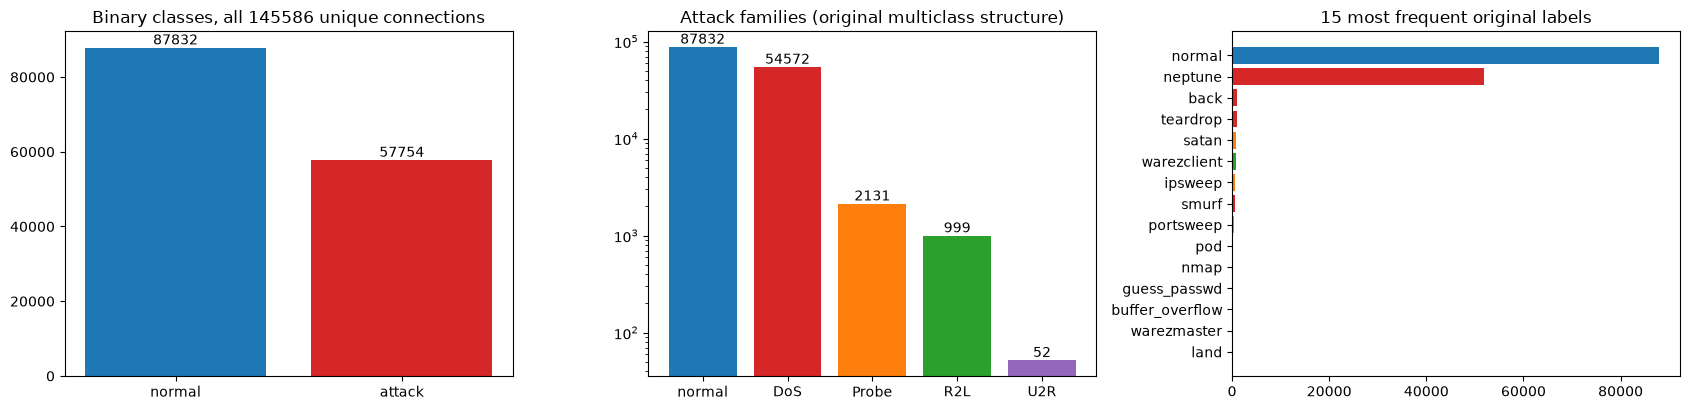

balanced sample of 6000 connections, TD=90 %, seed 42: connections per family


family,normal,DoS,Probe,R2L,U2R
train,2700,2552,96,49,3
test,300,281,10,9,0


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
vc = raw["binary"].map({0: "normal", 1: "attack"}).value_counts().reindex(["normal", "attack"])
axes[0].bar(vc.index, vc.values, color=["tab:blue", "tab:red"]); axes[0].set_title("Binary classes, all %d unique connections" % len(raw))
for i, v in enumerate(vc.values): axes[0].text(i, v, str(v), ha="center", va="bottom")
fc = raw["family"].value_counts().reindex(FAMILIES)
axes[1].bar(fc.index, fc.values, color=[FAM_COLOUR[f] for f in fc.index]); axes[1].set_title("Attack families (original multiclass structure)")
axes[1].set_yscale("log")
for i, v in enumerate(fc.values): axes[1].text(i, v, str(v), ha="center", va="bottom")
top = raw["label"].value_counts().head(15)[::-1]
axes[2].barh(top.index, top.values, color=[FAM_COLOUR[FAMILY[n]] for n in top.index]); axes[2].set_title("15 most frequent original labels")
plt.tight_layout(); plt.show()

tab = pd.DataFrame({"train": D0["tr"]["family"].value_counts(), "test": D0["te"]["family"].value_counts()}).reindex(FAMILIES).fillna(0).astype(int)
print(f"balanced sample of {len(D0['tr']) + len(D0['te'])} connections, TD={MAIN_TD} %, seed {D0['seed']}: connections per family")
display(tab.T)

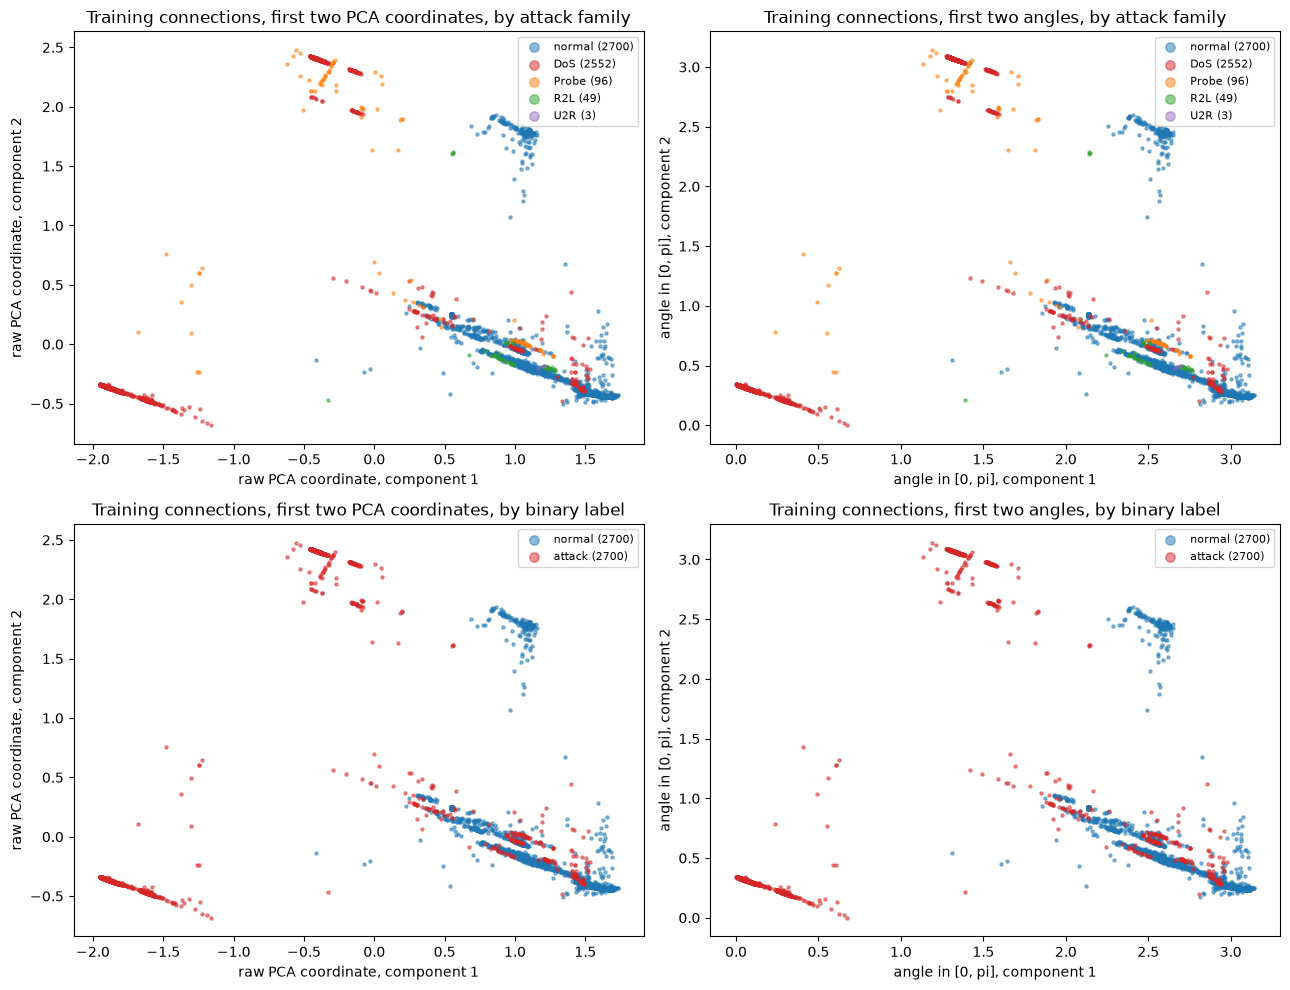

Every point is one real training connection (5400 in total). The two components already separate most attacks from normal traffic, but the classes overlap, which is why the plain QNN uses 6 components.


In [8]:
d = D0
fam_tr, bin_tr = d["tr"]["family"].to_numpy(), d["ytr"]
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
for row, (labels, order, colours, title) in enumerate([(fam_tr, FAMILIES, FAM_COLOUR, "attack family"),
                                                        (np.where(bin_tr == 1, "attack", "normal"), ["normal", "attack"],
                                                         {"normal": "tab:blue", "attack": "tab:red"}, "binary label")]):
    for col, (xy, xl) in enumerate([(d["Ptr"][:, :2], "raw PCA coordinate"), (d["Atr"][:, :2], "angle in [0, pi]")]):
        ax = axes[row, col]
        for c in order:
            m = labels == c
            ax.scatter(xy[m, 0], xy[m, 1], s=5, alpha=0.5, c=colours[c], label=f"{c} ({m.sum()})")
        ax.set_xlabel(f"{xl}, component 1"); ax.set_ylabel(f"{xl}, component 2")
        ax.set_title(f"Training connections, first two {'PCA coordinates' if col == 0 else 'angles'}, by {title}")
        ax.legend(fontsize=8, markerscale=3)
plt.tight_layout(); plt.show()
print("Every point is one real training connection (%d in total). The two components already separate most attacks from normal "
      "traffic, but the classes overlap, which is why the plain QNN uses %d components." % (len(fam_tr), N_QUBITS))

## 3. The paper's metrics and the sklearn baselines

The paper reports nine metrics, all derived from the confusion matrix with *attack* as the positive class: specificity
`TN/(TN+FP)`, sensitivity `TP/(TP+FN)`, accuracy, precision, F-measure, MCC, NPV `TN/(TN+FN)`, FPR `FP/(FP+TN)` and FNR
`FN/(FN+TP)`. Random Forest (100 trees) and SVM (RBF, `C = 1`) are trained on the plain QNN's six angles and on the full
preprocessed vector; they are the "classical baseline on identical inputs" of this repository's rules (the paper itself does
not use them).

In [9]:
def paper_metrics(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    dv = lambda a, b: a / b if b else 0.0
    prec = dv(tp, tp + fp); sens = dv(tp, tp + fn)
    return dict(specificity=dv(tn, tn + fp), sensitivity=sens, accuracy=(tp + tn) / (tp + tn + fp + fn), precision=prec,
                f_measure=dv(2 * prec * sens, prec + sens), mcc=float(matthews_corrcoef(y_true, y_pred)),
                npv=dv(tn, tn + fn), fpr=dv(fp, fp + tn), fnr=dv(fn, fn + tp), tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp))

METRICS = ["specificity", "sensitivity", "accuracy", "precision", "f_measure", "mcc", "npv", "fpr", "fnr"]
RES, PRED, HIST = {}, {}, {}        # keyed by (model name, td, seed)

def run_sklearn(td, seed):
    d = prepare(td, seed)
    for name, make, (Xtr, Xte) in [
            ("Random Forest [6 angles]", lambda: RandomForestClassifier(n_estimators=100, random_state=seed, n_jobs=2), (d["Atr"], d["Ate"])),
            ("SVM rbf [6 angles]",       lambda: SVC(kernel="rbf", C=1.0), (d["Atr"], d["Ate"])),
            ("Random Forest [all features]", lambda: RandomForestClassifier(n_estimators=100, random_state=seed, n_jobs=2), (d["Ztr"], d["Zte"])),
            ("SVM rbf [all features]",   lambda: SVC(kernel="rbf", C=1.0), (d["Ztr"], d["Zte"]))]:
        t0 = time.time(); m = make().fit(Xtr, d["ytr"]); pred = m.predict(Xte); dt = time.time() - t0
        RES[(name, td, seed)] = dict(**paper_metrics(d["yte"], pred), time_s=dt, params=-1)
        PRED[(name, td, seed)] = pred

t0 = time.time()
for td, seed in RUNS: run_sklearn(td, seed)
print("sklearn baselines done in %.1f s" % (time.time() - t0))
display(pd.DataFrame({k[0]: v for k, v in RES.items() if k[1:] == (MAIN_TD, SEEDS[0])}).T[METRICS + ["time_s"]].round(4))

sklearn baselines done in 33.3 s


,specificity,sensitivity,accuracy,precision,f_measure,mcc,npv,fpr,fnr,time_s
Random Forest [6 angles],0.9900,0.9867,0.9883,0.9900,0.9883,0.9767,0.9867,0.0100,0.0133,0.9809
SVM rbf [6 angles],0.9867,0.9500,0.9683,0.9862,0.9677,0.9373,0.9518,0.0133,0.0500,0.1934
Random Forest [all features],0.9967,0.9967,0.9967,0.9967,0.9967,0.9933,0.9967,0.0033,0.0033,1.9993
SVM rbf [all features],0.9867,0.9900,0.9883,0.9867,0.9884,0.9767,0.9900,0.0133,0.0100,1.1934


## 4. The improved CNN-based QNN

### 4.1 The W-HHSM-BN layer (a reconstruction)

The text of Eqs. (1) to (3) is garbled in the PDF, so the layer below is a **reconstruction from the visible fragments**
and is flagged as such everywhere. What is legible: (1) a piecewise "hard hyperbolic softmax" `f(z)` with branches for
`z >= 1`, `-1 < z < 1` (softmax `exp(z_i) / sum_j exp(z_j)`) and `z <= -1`; (2) `f'(z)` built from `w_max = 0.9`, `w_min = 0.4`
and `ln(1 + e^{f(z)})`; (3) `f''(z)` = the batch-normalised input `(z_i - mu_b) / sqrt(sigma_b^2 + eps)` combined with `f'(z)`.
We implement

* `f(z) = +1` for `z >= 1`, `-1` for `z <= -1`, and `softmax(z)` over the positions otherwise,
* `f'(z) = w_max ln(1 + e^{f}) / (w_min ln(1 + e^{-f}))`, a bounded gate in [0.54, 9.4],
* `f''(z) = BatchNorm(z) * f'(z)`.

An ablation in Section 8 replaces this layer with plain batch normalisation to see whether it matters.

### 4.2 The rest of the network and the quantum part

`Conv1D(1->8, k=3) -> BN -> tanh -> LeakyReLU -> scaled dot-product (self-attention over the positions, residual) ->
AvgPool(2) -> W-HHSM-BN -> Flatten -> Dropout -> Dense(6) -> pi * sigmoid` produces six angles; they are the inputs of the
quantum circuit `RY(x_i)` on qubit *i* -> 3 x `StronglyEntanglingLayers` -> `<Z_0>`. The logit of the attack class is
`a <Z_0> + b` (two trainable scalars). CNN and circuit are trained **jointly** with Adam and binary cross-entropy.
The plain **QNN** of the paper is the same circuit fed with the six PCA angles instead.

In [10]:
# ---------- improved CNN front end ----------
class ScaledDotProduct(nn.Module):
    # self-attention over the positions of a (B, C, L) feature map, softmax(Q K^T / sqrt(C)) V with Q = K = V = features
    def forward(self, x):
        t = x.transpose(1, 2)                                              # (B, L, C)
        att = torch.softmax(t @ t.transpose(1, 2) / math.sqrt(t.shape[-1]), dim=-1)
        return x + (att @ t).transpose(1, 2)                               # CHOICE: residual connection

class WHHSMBN(nn.Module):
    # RECONSTRUCTION of Eqs. (1)-(3) of the paper (the PDF text of the equations is garbled); see the markdown above
    def __init__(self, channels, w_max=0.9, w_min=0.4):
        super().__init__(); self.bn = nn.BatchNorm1d(channels); self.w_max, self.w_min = w_max, w_min
    def forward(self, z):
        sm = torch.softmax(z, dim=-1)
        f = torch.where(z >= 1, torch.ones_like(z), torch.where(z <= -1, -torch.ones_like(z), sm))      # Eq. (1)
        fp = self.w_max * F.softplus(f) / (self.w_min * F.softplus(-f))                                   # Eq. (2)
        return self.bn(z) * fp                                                                            # Eq. (3)

class ImprovedCNN(nn.Module):
    def __init__(self, n_in, n_out, whhsm=True, filters=8):
        super().__init__()
        self.conv = nn.Conv1d(1, filters, 3, padding=1); self.bn = nn.BatchNorm1d(filters)
        self.att = ScaledDotProduct(); self.pool = nn.AvgPool1d(2)
        self.layer = WHHSMBN(filters) if whhsm else nn.BatchNorm1d(filters)
        self.drop = nn.Dropout(DROPOUT); self.dense = nn.Linear(filters * (n_in // 2), n_out)
    def forward(self, x):
        h = F.leaky_relu(torch.tanh(self.bn(self.conv(x.unsqueeze(1)))))
        h = self.layer(self.pool(self.att(h)))
        return self.dense(self.drop(h.flatten(1)))

# ---------- quantum part ----------
dev = qml.device("default.qubit", wires=N_QUBITS)
def make_qnode(diff_method="backprop"):
    @qml.qnode(qml.device("default.qubit", wires=N_QUBITS), interface="torch", diff_method=diff_method)
    def circuit(x, w):
        qml.AngleEmbedding(x, wires=range(N_QUBITS), rotation="Y")        # data encoding: RY(x_i) on qubit i
        qml.StronglyEntanglingLayers(w, wires=range(N_QUBITS))            # CHOICE: trainable rotations + CNOT ring (paper: unspecified)
        return qml.expval(qml.PauliZ(0))                                  # measurement decoded into the output
    return circuit

class QHead(nn.Module):
    def __init__(self, seed, diff_method="backprop"):
        super().__init__()
        self.circuit = make_qnode(diff_method)
        g = torch.Generator().manual_seed(seed)
        self.weights = nn.Parameter(0.1 * torch.randn(Q_LAYERS, N_QUBITS, 3, generator=g, dtype=torch.float64))   # CHOICE: N(0, 0.1^2)
        self.scale = nn.Parameter(torch.tensor(2.0, dtype=torch.float64)); self.bias = nn.Parameter(torch.zeros((), dtype=torch.float64))
    def forward(self, a):
        return self.scale * self.circuit(a, self.weights) + self.bias     # logit of "attack"

class QModel(nn.Module):
    # front end -> 6 angles -> circuit.  Plain QNN: front = identity (inputs are already PCA angles).
    def __init__(self, front, seed, angles_from_front, diff_method="backprop"):
        super().__init__(); self.front, self.head, self.afn = front, QHead(seed, diff_method), angles_from_front
    def angles(self, x): return self.afn(self.front(x))
    def forward(self, x): return self.head(self.angles(x))

class CNNClassicalHead(nn.Module):
    # ablation: the same improved CNN, but a classical linear head instead of the quantum circuit
    def __init__(self, n_in, whhsm=True):
        super().__init__(); self.front = ImprovedCNN(n_in, N_QUBITS, whhsm); self.fc = nn.Linear(N_QUBITS, 1)
    def forward(self, x): return self.fc(math.pi * torch.sigmoid(self.front(x))).squeeze(-1)

def make_improved(n_in, seed, whhsm=True, diff_method="backprop"):
    return QModel(ImprovedCNN(n_in, N_QUBITS, whhsm), seed, lambda z: math.pi * torch.sigmoid(z), diff_method)   # CHOICE: angles = pi*sigmoid
def make_plain_qnn(seed, diff_method="backprop"):
    return QModel(nn.Identity(), seed, lambda z: z, diff_method)

n_params = lambda m: int(sum(p.numel() for p in m.parameters() if p.requires_grad))
n_in = len(D0["names"])
print("input features:", n_in)
print("improved CNN-QNN trainable parameters:", n_params(make_improved(n_in, SEED)), "(CNN front end %d + circuit/head %d)" %
      (n_params(make_improved(n_in, SEED).front), n_params(make_improved(n_in, SEED).head)))
print("plain QNN trainable parameters       :", n_params(make_plain_qnn(SEED)))

input features: 105
improved CNN-QNN trainable parameters: 2622 (CNN front end 2566 + circuit/head 56)
plain QNN trainable parameters       : 56


## Quantum Circuit Architecture

Both quantum detectors execute the **same** circuit; they differ only in who produces the six rotation angles (the improved
CNN for the proposed model, PCA for the plain QNN). The paper gives no gate-level description of its QNN ("qubit state altered
by rotation gates with connecting gates", Fig. 2 shows a generic box), so the variational block is our choice:

| Part | Gates |
|---|---|
| Encoding | `RY(x_i)` on qubit *i* (`AngleEmbedding`, rotation Y), 6 qubits |
| Trainable block | 3 x `StronglyEntanglingLayers`: a general rotation `Rot(phi, theta, omega)` on every qubit, then CNOTs between qubit *i* and *i + r* (range *r* = 1, 2, 3 in the three layers) |
| Measurement | expectation value of Pauli-Z on qubit 0, mapped by `a <Z_0> + b` to the attack logit |

The cells below draw the QNode that is actually executed (once on the angles produced by the untrained improved CNN for a
real training connection, once on a real PCA-angle vector of the plain QNN), decompose it into the gates the simulator
applies, print qubit count, depth and parameter counts, and check that the back-propagated gradient used for training equals
the parameter-shift gradient used on quantum hardware.

In [11]:
m_imp = make_improved(n_in, SEED); m_qnn = make_plain_qnn(SEED)
m_imp.eval()
x_real = torch.tensor(D0["Ztr"][:1], dtype=torch.float64); m_imp = m_imp.double()
with torch.no_grad():
    a_imp = m_imp.angles(x_real)[0]                                   # angles the improved CNN produces for a real training connection
a_qnn = torch.tensor(D0["Atr"][0], dtype=torch.float64)               # angles the plain QNN receives for the same connection
rows = []
for name, m, a in [("improved CNN-QNN", m_imp, a_imp), ("plain QNN", m_qnn, a_qnn)]:
    res = qml.specs(m.head.circuit, level="device")(a, m.head.weights)["resources"]
    rows.append(dict(model=name, qubits=N_QUBITS, circuit_depth_device_level=res.depth, gates=res.num_gates,
                     circuit_parameters=int(m.head.weights.numel()), head_scalars=2, total_trainable_parameters=n_params(m)))
display(pd.DataFrame(rows))
print("angles from the improved CNN for training connection 0:", np.round(a_imp.numpy(), 3))
print("PCA angles of the same connection (plain QNN)        :", np.round(a_qnn.numpy(), 3))

,model,qubits,circuit_depth_device_level,gates,circuit_parameters,head_scalars,total_trainable_parameters
0,improved CNN-QNN,6,15,42,54,2,2622
1,plain QNN,6,15,42,54,2,56


angles from the improved CNN for training connection 0: [1.546 1.55  1.75  1.217 1.986 0.199]
PCA angles of the same connection (plain QNN)        : [0.043 0.321 2.302 1.236 2.223 1.742]


0: ─╭AngleEmbedding(M0)─╭StronglyEntanglingLayers(M1)─┤  <Z>
1: ─├AngleEmbedding(M0)─├StronglyEntanglingLayers(M1)─┤     
2: ─├AngleEmbedding(M0)─├StronglyEntanglingLayers(M1)─┤     
3: ─├AngleEmbedding(M0)─├StronglyEntanglingLayers(M1)─┤     
4: ─├AngleEmbedding(M0)─├StronglyEntanglingLayers(M1)─┤     
5: ─╰AngleEmbedding(M0)─╰StronglyEntanglingLayers(M1)─┤     


Matplotlib is building the font cache; this may take a moment.


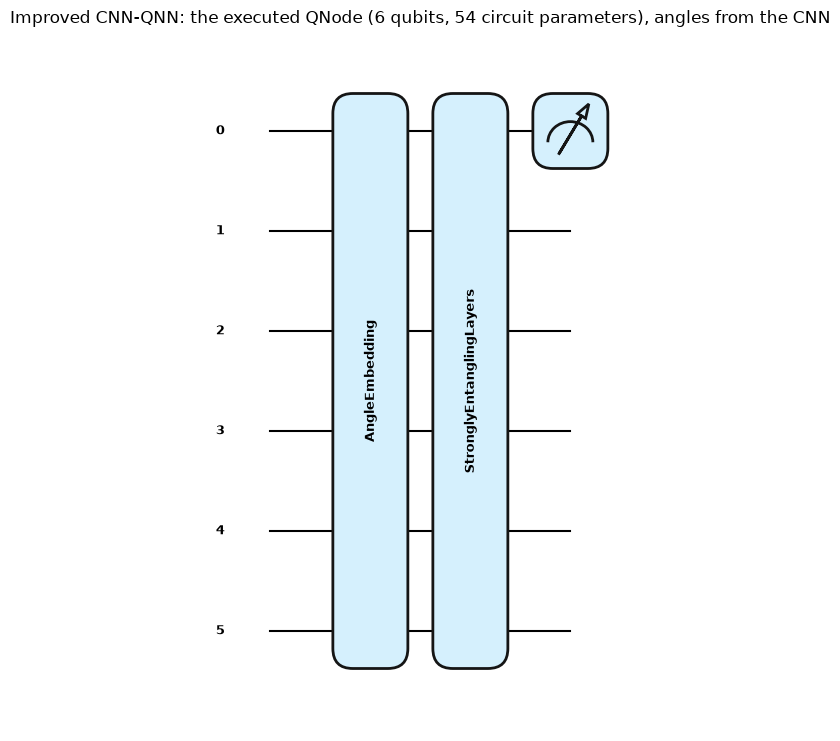

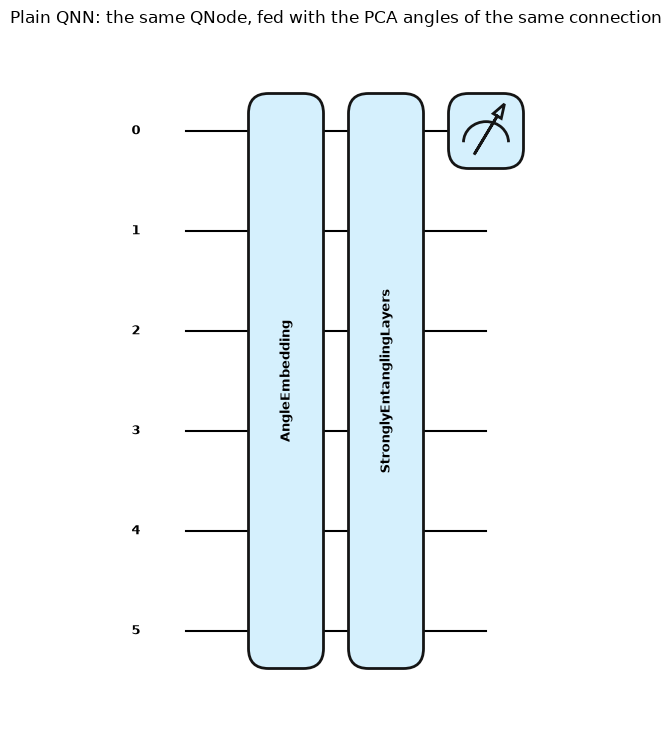

In [12]:
print(qml.draw(m_imp.head.circuit, max_length=150, show_matrices=False)(a_imp, m_imp.head.weights))
fig, ax = qml.draw_mpl(m_imp.head.circuit, decimals=2, style="pennylane", fontsize=9)(a_imp, m_imp.head.weights)
fig.suptitle(f"Improved CNN-QNN: the executed QNode ({N_QUBITS} qubits, {m_imp.head.weights.numel()} circuit parameters), angles from the CNN", y=1.03)
plt.show()
fig, ax = qml.draw_mpl(m_qnn.head.circuit, decimals=2, style="pennylane", fontsize=9)(a_qnn, m_qnn.head.weights)
fig.suptitle("Plain QNN: the same QNode, fed with the PCA angles of the same connection", y=1.03)
plt.show()

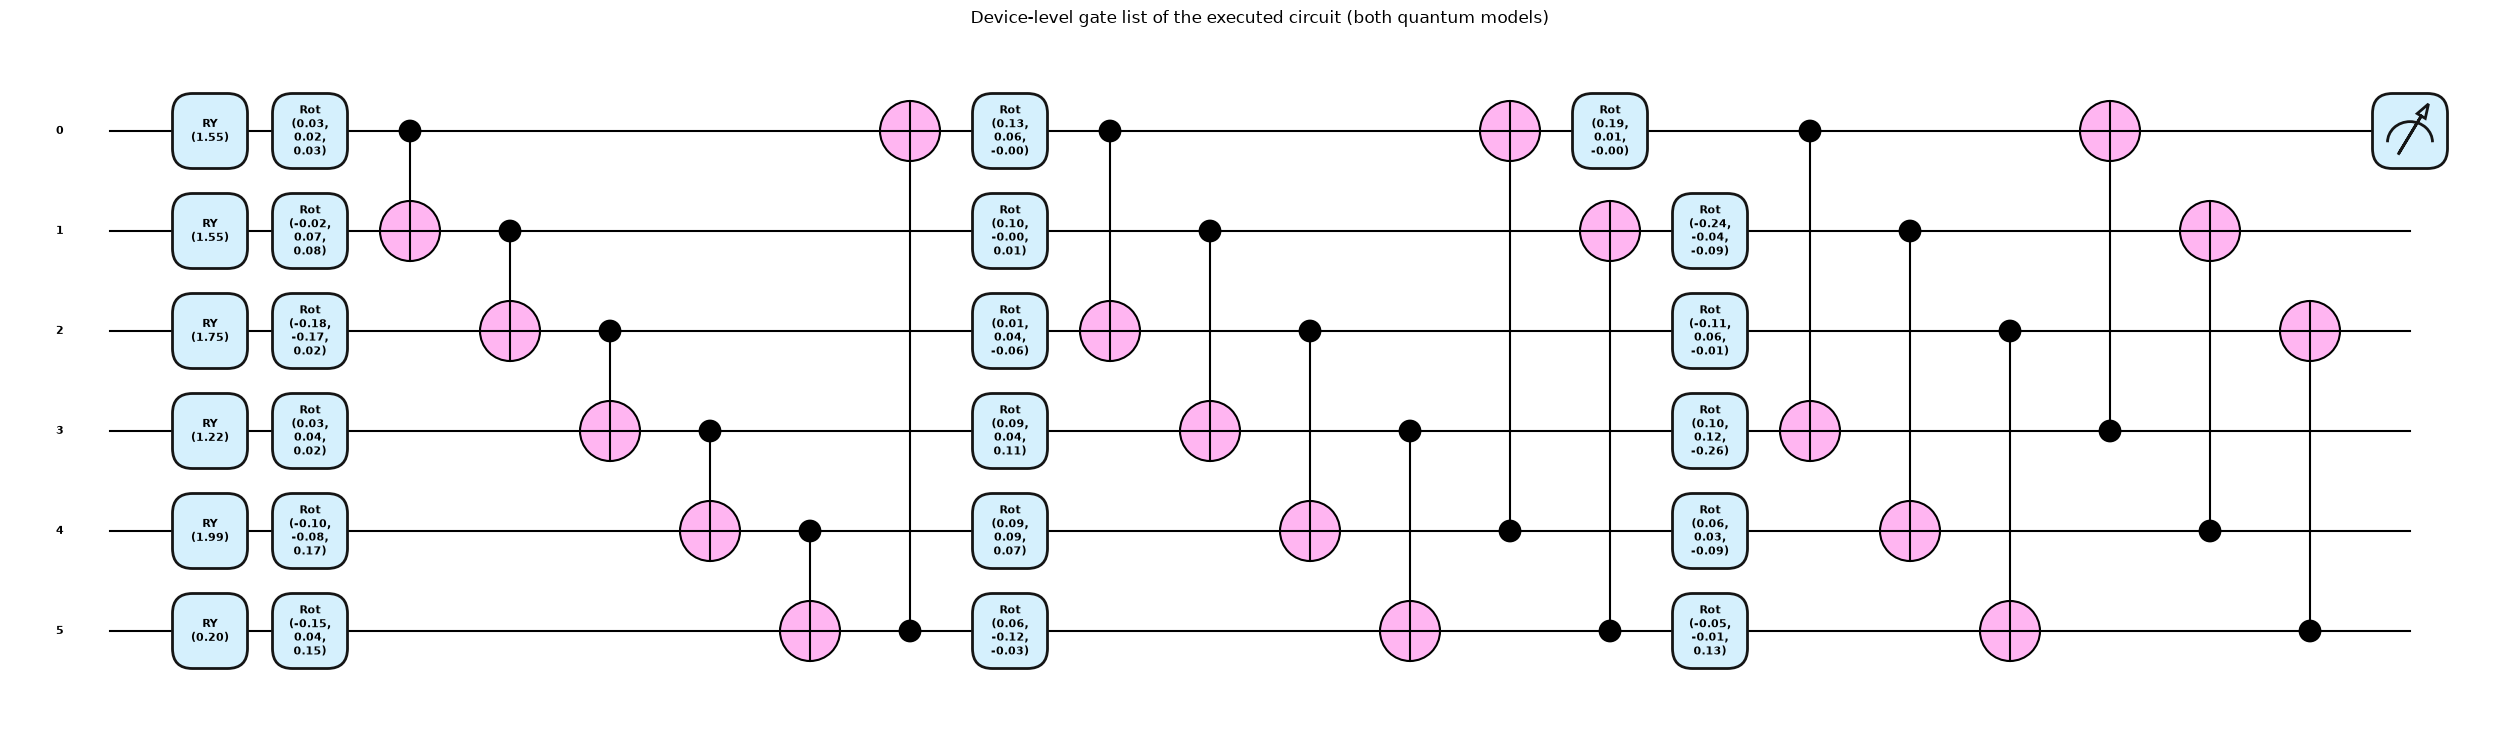

max |grad_backprop - grad_parameter_shift| over all 56 parameters = 2.22e-16


In [13]:
# Decomposed into the gates the simulator applies (device level): RY, Rot (RZ-RY-RZ) and CNOT.
fig, ax = qml.draw_mpl(m_imp.head.circuit, level="device", decimals=2, style="pennylane", fontsize=8)(a_imp, m_imp.head.weights)
fig.suptitle("Device-level gate list of the executed circuit (both quantum models)", y=1.03)
plt.show()

# Equivalence check: training uses back-propagation through the simulator; quantum hardware uses the parameter-shift rule.
A4 = torch.tensor(D0["Atr"][:4], dtype=torch.float64); y4 = torch.tensor(D0["ytr"][:4], dtype=torch.float64)
grads = {}
for dm in ("backprop", "parameter-shift"):
    mm = make_plain_qnn(SEED, dm).double()
    loss = F.binary_cross_entropy_with_logits(mm(A4), y4); loss.backward()
    grads[dm] = torch.cat([p.grad.flatten() for p in mm.parameters()]).numpy()
gap = np.abs(grads["backprop"] - grads["parameter-shift"]).max()
print(f"max |grad_backprop - grad_parameter_shift| over all {grads['backprop'].size} parameters = {gap:.2e}")
assert gap < 1e-8

## 5. The comparators: Bi-GRU, AlexNet, DenseNet, GhostNet

The paper does not give the architectures of the four classical networks. We use compact 1-D versions that keep each
network's defining idea (bidirectional recurrence; stacked convolutions with large fully connected head; dense
concatenation; ghost modules = cheap depthwise features), all receive the same preprocessed vector as the improved CNN and
are trained with Adam and binary cross-entropy. They are intentionally small (a few thousand parameters), like the proposed
CNN front end.

In [14]:
class BiGRU(nn.Module):
    def __init__(self, n_in, step=5, hidden=16):                   # CHOICE: the vector is read as T = n_in/5 steps of 5 features
        super().__init__(); self.step = step; self.T = math.ceil(n_in / step); self.pad = self.T * step - n_in
        self.gru = nn.GRU(step, hidden, batch_first=True, bidirectional=True); self.fc = nn.Linear(2 * hidden, 1)
    def forward(self, x):
        _, h = self.gru(F.pad(x, (0, self.pad)).view(len(x), self.T, self.step))
        return self.fc(torch.cat([h[0], h[1]], dim=1)).squeeze(-1)

class AlexNet1D(nn.Module):
    def __init__(self, n_in):
        super().__init__()
        self.f = nn.Sequential(nn.Conv1d(1, 16, 5, padding=2), nn.ReLU(), nn.MaxPool1d(2), nn.Conv1d(16, 32, 3, padding=1), nn.ReLU(),
                               nn.MaxPool1d(2), nn.Conv1d(32, 48, 3, padding=1), nn.ReLU(), nn.Conv1d(48, 32, 3, padding=1), nn.ReLU(),
                               nn.MaxPool1d(2), nn.AdaptiveAvgPool1d(4))
        self.c = nn.Sequential(nn.Dropout(DROPOUT), nn.Linear(128, 64), nn.ReLU(), nn.Dropout(DROPOUT), nn.Linear(64, 1))
    def forward(self, x): return self.c(self.f(x.unsqueeze(1)).flatten(1)).squeeze(-1)

class DenseBlock(nn.Module):
    def __init__(self, c, growth=8, layers=3):
        super().__init__(); self.layers = nn.ModuleList()
        for i in range(layers):
            self.layers.append(nn.Sequential(nn.BatchNorm1d(c + i * growth), nn.ReLU(), nn.Conv1d(c + i * growth, growth, 3, padding=1)))
        self.out = c + layers * growth
    def forward(self, x):
        for l in self.layers: x = torch.cat([x, l(x)], dim=1)
        return x

class DenseNet1D(nn.Module):
    def __init__(self, n_in):
        super().__init__(); self.stem = nn.Conv1d(1, 8, 3, padding=1)
        b1 = DenseBlock(8); b2 = DenseBlock(b1.out // 2)
        self.body = nn.Sequential(b1, nn.BatchNorm1d(b1.out), nn.ReLU(), nn.Conv1d(b1.out, b1.out // 2, 1), nn.AvgPool1d(2), b2,
                                  nn.BatchNorm1d(b2.out), nn.ReLU(), nn.AdaptiveAvgPool1d(1))
        self.fc = nn.Linear(b2.out, 1)
    def forward(self, x): return self.fc(self.body(self.stem(x.unsqueeze(1))).flatten(1)).squeeze(-1)

class Ghost(nn.Module):
    def __init__(self, cin, cout):
        super().__init__(); h = cout // 2
        self.prim = nn.Sequential(nn.Conv1d(cin, h, 1), nn.BatchNorm1d(h), nn.ReLU())
        self.cheap = nn.Sequential(nn.Conv1d(h, h, 3, padding=1, groups=h), nn.BatchNorm1d(h), nn.ReLU())
    def forward(self, x):
        p = self.prim(x); return torch.cat([p, self.cheap(p)], dim=1)

class GhostNet1D(nn.Module):
    def __init__(self, n_in):
        super().__init__()
        self.f = nn.Sequential(nn.Conv1d(1, 8, 3, stride=2, padding=1), nn.BatchNorm1d(8), nn.ReLU(), Ghost(8, 16), Ghost(16, 32),
                               nn.MaxPool1d(2), Ghost(32, 32), nn.AdaptiveAvgPool1d(1))
        self.fc = nn.Linear(32, 1)
    def forward(self, x): return self.fc(self.f(x.unsqueeze(1)).flatten(1)).squeeze(-1)

for nm, mk in [("Bi-GRU", BiGRU), ("AlexNet", AlexNet1D), ("DenseNet", DenseNet1D), ("GhostNet", GhostNet1D)]:
    print(f"{nm:9s} trainable parameters: {n_params(mk(n_in))}")

Bi-GRU    trainable parameters: 2241
AlexNet   trainable parameters: 19281
DenseNet  trainable parameters: 3913


GhostNet  trainable parameters: 1273


## 6. Training everything

One generic loop trains every model: mini-batches of 256, Adam, binary cross-entropy on the attack logit, fixed epoch
budget (the paper gives none). The hybrid models use two learning rates (circuit weights 0.05, CNN weights 0.005). After
each epoch the accuracy on the first 1,000 *training* rows is logged for the convergence plot; the test split is used once,
after training. For every (TD, seed) run a new balanced sample, split and initialisation is drawn.

In [15]:
def predict_logits(model, X, dtype, chunk=4096):
    model.eval(); out = []
    with torch.no_grad():
        for i in range(0, len(X), chunk):
            out.append(model(torch.as_tensor(X[i:i + chunk], dtype=dtype)).reshape(-1).numpy())
    return np.concatenate(out)

def recalibrate_bn(model, X, dtype):
    # CHOICE: after training, re-estimate the batch-norm running statistics over the whole training set (cumulative average).
    # With only a few hundred Adam steps the exponential running averages lag behind the weights, and a deep BN network then
    # collapses to one class at test time (seen for DenseNet / GhostNet in a first run) although it is fine in training mode.
    bns = [m for m in model.modules() if isinstance(m, nn.modules.batchnorm._BatchNorm)]
    if not bns: return
    for m in bns: m.reset_running_stats(); m.momentum = None
    model.train()
    with torch.no_grad():
        for i in range(0, len(X), 512): model(X[i:i + 512])
    model.eval()

def train_net(name, make, td, seed, epochs, inputs="all", log=True):
    d = prepare(td, seed)
    Xtr, Xte = (d["Ztr"], d["Zte"]) if inputs == "all" else (d["Atr"], d["Ate"])
    torch.manual_seed(seed); np.random.seed(seed)
    model = make(Xtr.shape[1]); quantum = isinstance(model, QModel)   # input width differs a little between splits (constant-column drop)
    dtype = torch.float64 if quantum else torch.float32
    model = model.to(dtype)
    if quantum:
        groups = [dict(params=list(model.head.parameters()), lr=LR_CIRCUIT)]
        fp = list(model.front.parameters())
        if fp: groups.append(dict(params=fp, lr=LR_FRONT))
    else:
        groups = [dict(params=list(model.parameters()), lr=LR_CLASSICAL)]
    opt = torch.optim.Adam(groups)
    Xt = torch.as_tensor(Xtr, dtype=dtype); Yt = torch.as_tensor(d["ytr"], dtype=dtype)
    g = torch.Generator().manual_seed(seed); hist = []; t0 = time.time()
    for ep in range(epochs):
        model.train(); perm = torch.randperm(len(Xt), generator=g); tot = 0.0
        for i in range(0, len(Xt), BATCH):
            idx = perm[i:i + BATCH]
            if len(idx) < 8: continue
            loss = F.binary_cross_entropy_with_logits(model(Xt[idx]).reshape(-1), Yt[idx])
            opt.zero_grad(); loss.backward(); opt.step(); tot += loss.item() * len(idx)
        acc = float(((predict_logits(model, Xtr[:PROBE], dtype) > 0).astype(int) == d["ytr"][:PROBE]).mean())
        hist.append((tot / len(Xt), acc))
        if log and (ep == 0 or ep + 1 == epochs or (ep + 1) % 3 == 0):
            print(f"    {name} TD={td} seed={seed} epoch {ep+1:2d}/{epochs} loss {hist[-1][0]:.4f} probe-acc {acc:.4f} ({time.time()-t0:.0f} s)", flush=True)
    recalibrate_bn(model, Xt, dtype)
    train_s = time.time() - t0
    t1 = time.time(); pred = (predict_logits(model, Xte, dtype) > 0).astype(int); pred_s = time.time() - t1
    RES[(name, td, seed)] = dict(**paper_metrics(d["yte"], pred), time_s=train_s + pred_s, params=n_params(model))
    PRED[(name, td, seed)] = pred; HIST[(name, td, seed)] = hist
    return model

MODELS = {   # name -> (constructor(seed), inputs, epochs)
    "Bi-GRU":           (lambda s, n: BiGRU(n),               "all",    EPOCHS_C),
    "AlexNet":          (lambda s, n: AlexNet1D(n),           "all",    EPOCHS_C),
    "DenseNet":         (lambda s, n: DenseNet1D(n),          "all",    EPOCHS_C),
    "GhostNet":         (lambda s, n: GhostNet1D(n),          "all",    EPOCHS_C),
    "QNN":              (lambda s, n: make_plain_qnn(s),      "angles", EPOCHS_Q),
    "Improved CNN-QNN": (lambda s, n: make_improved(n, s),    "all",    EPOCHS_Q),
}
PAPER_ORDER = list(MODELS)

def run_one(td, seed):
    print(f"=== run TD={td} %, seed {seed} ===", flush=True); t_run = time.time()
    for name, (mk, inputs, ep) in MODELS.items():
        train_net(name, (lambda n, mk=mk, seed=seed: mk(seed, n)), td, seed, ep, inputs)
        r = RES[(name, td, seed)]
        print(f"  -> {name:17s} acc {r['accuracy']:.4f}  F {r['f_measure']:.4f}  MCC {r['mcc']:.4f}  FPR {r['fpr']:.4f}  time {r['time_s']:.0f} s", flush=True)
    print("run finished in %.1f min" % ((time.time() - t_run) / 60))

In [16]:
# one cell per (TD, seed) run, so that the log shows progress
if (60, 42) in RUNS: run_one(60, 42)

=== run TD=60 %, seed 42 ===


    Bi-GRU TD=60 seed=42 epoch  1/8 loss 0.6820 probe-acc 0.9210 (9 s)


    Bi-GRU TD=60 seed=42 epoch  3/8 loss 0.4624 probe-acc 0.9360 (26 s)


    Bi-GRU TD=60 seed=42 epoch  6/8 loss 0.1244 probe-acc 0.9460 (62 s)


    Bi-GRU TD=60 seed=42 epoch  8/8 loss 0.1098 probe-acc 0.9560 (80 s)


...

    Improved CNN-QNN TD=60 seed=42 epoch  1/6 loss 0.3307 probe-acc 0.9670 (21 s)


    Improved CNN-QNN TD=60 seed=42 epoch  3/6 loss 0.1175 probe-acc 0.9740 (54 s)


    Improved CNN-QNN TD=60 seed=42 epoch  6/6 loss 0.0907 probe-acc 0.9750 (105 s)


  -> Improved CNN-QNN  acc 0.9758  F 0.9755  MCC 0.9519  FPR 0.0125  time 114 s


run finished in 8.0 min


In [17]:
# one cell per (TD, seed) run, so that the log shows progress
if (75, 42) in RUNS: run_one(75, 42)

=== run TD=75 %, seed 42 ===


    Bi-GRU TD=75 seed=42 epoch  1/8 loss 0.6638 probe-acc 0.9350 (9 s)


    Bi-GRU TD=75 seed=42 epoch  3/8 loss 0.3635 probe-acc 0.9400 (25 s)


    Bi-GRU TD=75 seed=42 epoch  6/8 loss 0.1223 probe-acc 0.9650 (51 s)


    Bi-GRU TD=75 seed=42 epoch  8/8 loss 0.1006 probe-acc 0.9810 (75 s)


...

    Improved CNN-QNN TD=75 seed=42 epoch  1/6 loss 0.3079 probe-acc 0.9120 (21 s)


    Improved CNN-QNN TD=75 seed=42 epoch  3/6 loss 0.1125 probe-acc 0.9840 (65 s)


    Improved CNN-QNN TD=75 seed=42 epoch  6/6 loss 0.0883 probe-acc 0.9840 (117 s)


  -> Improved CNN-QNN  acc 0.9800  F 0.9800  MCC 0.9600  FPR 0.0200  time 126 s


run finished in 12.3 min


In [18]:
# one cell per (TD, seed) run, so that the log shows progress
if (90, 42) in RUNS: run_one(90, 42)

=== run TD=90 %, seed 42 ===


    Bi-GRU TD=90 seed=42 epoch  1/8 loss 0.6585 probe-acc 0.9230 (8 s)


    Bi-GRU TD=90 seed=42 epoch  3/8 loss 0.2404 probe-acc 0.9530 (20 s)


    Bi-GRU TD=90 seed=42 epoch  6/8 loss 0.1066 probe-acc 0.9670 (31 s)


    Bi-GRU TD=90 seed=42 epoch  8/8 loss 0.0899 probe-acc 0.9800 (41 s)


...

    Improved CNN-QNN TD=90 seed=42 epoch  1/6 loss 0.3007 probe-acc 0.8680 (14 s)


    Improved CNN-QNN TD=90 seed=42 epoch  3/6 loss 0.1145 probe-acc 0.9770 (69 s)


    Improved CNN-QNN TD=90 seed=42 epoch  6/6 loss 0.0866 probe-acc 0.9830 (122 s)


  -> Improved CNN-QNN  acc 0.9817  F 0.9816  MCC 0.9634  FPR 0.0133  time 129 s


run finished in 6.3 min


In [19]:
# one cell per (TD, seed) run, so that the log shows progress
if (90, 43) in RUNS: run_one(90, 43)

=== run TD=90 %, seed 43 ===


    Bi-GRU TD=90 seed=43 epoch  1/8 loss 0.6640 probe-acc 0.9510 (4 s)


    Bi-GRU TD=90 seed=43 epoch  3/8 loss 0.2346 probe-acc 0.9330 (13 s)


    Bi-GRU TD=90 seed=43 epoch  6/8 loss 0.1258 probe-acc 0.9600 (24 s)


    Bi-GRU TD=90 seed=43 epoch  8/8 loss 0.0974 probe-acc 0.9520 (29 s)


...

    Improved CNN-QNN TD=90 seed=43 epoch  1/6 loss 0.2230 probe-acc 0.9680 (16 s)


    Improved CNN-QNN TD=90 seed=43 epoch  3/6 loss 0.1010 probe-acc 0.9730 (49 s)


    Improved CNN-QNN TD=90 seed=43 epoch  6/6 loss 0.0668 probe-acc 0.9840 (112 s)


  -> Improved CNN-QNN  acc 0.9850  F 0.9849  MCC 0.9701  FPR 0.0067  time 117 s


run finished in 5.8 min


In [20]:
# one cell per (TD, seed) run, so that the log shows progress
if (90, 44) in RUNS: run_one(90, 44)

=== run TD=90 %, seed 44 ===


    Bi-GRU TD=90 seed=44 epoch  1/8 loss 0.6593 probe-acc 0.9530 (3 s)


    Bi-GRU TD=90 seed=44 epoch  3/8 loss 0.2377 probe-acc 0.9560 (7 s)


    Bi-GRU TD=90 seed=44 epoch  6/8 loss 0.1130 probe-acc 0.9680 (18 s)


    Bi-GRU TD=90 seed=44 epoch  8/8 loss 0.0955 probe-acc 0.9730 (32 s)


...

    Improved CNN-QNN TD=90 seed=44 epoch  1/6 loss 0.3945 probe-acc 0.9650 (20 s)


    Improved CNN-QNN TD=90 seed=44 epoch  3/6 loss 0.1262 probe-acc 0.9800 (56 s)


    Improved CNN-QNN TD=90 seed=44 epoch  6/6 loss 0.1068 probe-acc 0.9780 (112 s)


  -> Improved CNN-QNN  acc 0.9900  F 0.9899  MCC 0.9801  FPR 0.0033  time 122 s


run finished in 7.0 min


In [21]:
missing = [r for r in RUNS if ("Improved CNN-QNN",) + r not in RES]
assert not missing, missing
print("all", len(RUNS), "runs done:", RUNS)

all 5 runs done: [(60, 42), (75, 42), (90, 42), (90, 43), (90, 44)]


## 7. Results: the paper's Figs. 3 to 5 and Table I

Fig. 3 (specificity, sensitivity, accuracy, precision), Fig. 4 (F-measure, MCC, NPV) and Fig. 5 (FPR, FNR) are bar charts
over the training-data ratio TD for the six detectors. They are redrawn from the runs above (seed `SEEDS[0]`; at TD = 90 %
the table below averages the seeds). Table I summarises the accuracy over all runs of a model.

In [22]:
def mean_over_seeds(name, td, metric):
    v = [RES[(name, td, s)][metric] for s in (SEEDS if td == MAIN_TD else SEEDS[:1]) if (name, td, s) in RES]
    return float(np.mean(v)), float(np.std(v))

rows = []
for name in PAPER_ORDER:
    row = {"model": name}
    for m in METRICS:
        mu, sd = mean_over_seeds(name, MAIN_TD, m)
        row[m] = f"{mu:.4f} +- {sd:.4f}" if len(SEEDS) > 1 else f"{mu:.4f}"
    row["time_s"] = round(mean_over_seeds(name, MAIN_TD, "time_s")[0], 1); row["params"] = RES[(name, MAIN_TD, SEEDS[0])]["params"]
    rows.append(row)
print(f"Test-set metrics at TD = {MAIN_TD} % (mean +- std over seeds {SEEDS}; attack = positive class)")
display(pd.DataFrame(rows))

Test-set metrics at TD = 90 % (mean +- std over seeds [42, 43, 44]; attack = positive class)


,model,specificity,sensitivity,accuracy,precision,f_measure,mcc,npv,fpr,fnr,time_s,params
0,Bi-GRU,0.9789 +- 0.0166,0.9578 +- 0.0057,0.9683 +- 0.0111,0.9786 +- 0.0167,0.9681 +- 0.0111,0.9369 +- 0.0225,0.9586 +- 0.0060,0.0211 +- 0.0166,0.0422 +- 0.0057,33.9,2241
1,AlexNet,0.9867 +- 0.0082,0.9756 +- 0.0134,0.9811 +- 0.0103,0.9865 +- 0.0083,0.9810 +- 0.0104,0.9623 +- 0.0205,0.9759 +- 0.0131,0.0133 +- 0.0082,0.0244 +- 0.0134,38.2,19281
2,DenseNet,0.9844 +- 0.0031,0.9900 +- 0.0072,0.9872 +- 0.0021,0.9846 +- 0.0029,0.9872 +- 0.0021,0.9745 +- 0.0042,0.9900 +- 0.0072,0.0156 +- 0.0031,0.0100 +- 0.0072,106.2,3913
3,GhostNet,0.9900 +- 0.0072,0.9822 +- 0.0126,0.9861 +- 0.0098,0.9899 +- 0.0073,0.9860 +- 0.0099,0.9723 +- 0.0197,0.9824 +- 0.0124,0.0100 +- 0.0072,0.0178 +- 0.0126,40.5,1273
4,QNN,0.9844 +- 0.0068,0.9144 +- 0.0185,0.9494 +- 0.0122,0.9832 +- 0.0074,0.9475 +- 0.0129,0.9012 +- 0.0237,0.9202 +- 0.0164,0.0156 +- 0.0068,0.0856 +- 0.0185,42.1,56
5,Improved CNN-QNN,0.9922 +- 0.0042,0.9789 +- 0.0031,0.9856 +- 0.0034,0.9921 +- 0.0042,0.9855 +- 0.0034,0.9712 +- 0.0069,0.9792 +- 0.0031,0.0078 +- 0.0042,0.0211 +- 0.0031,122.5,2622


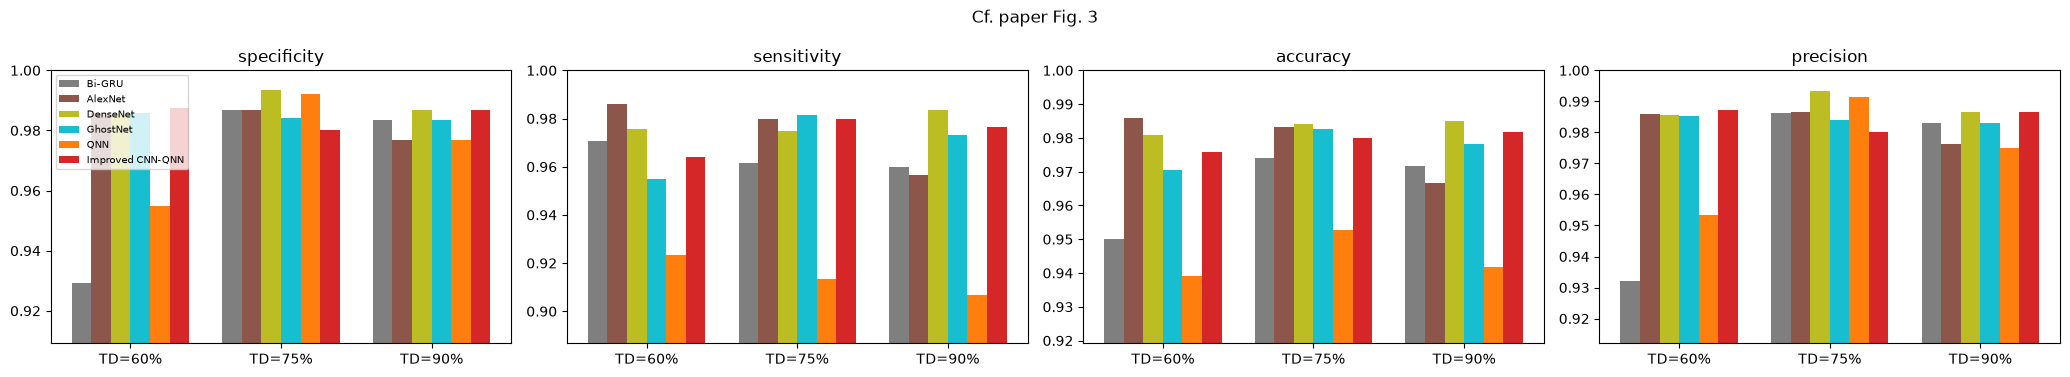

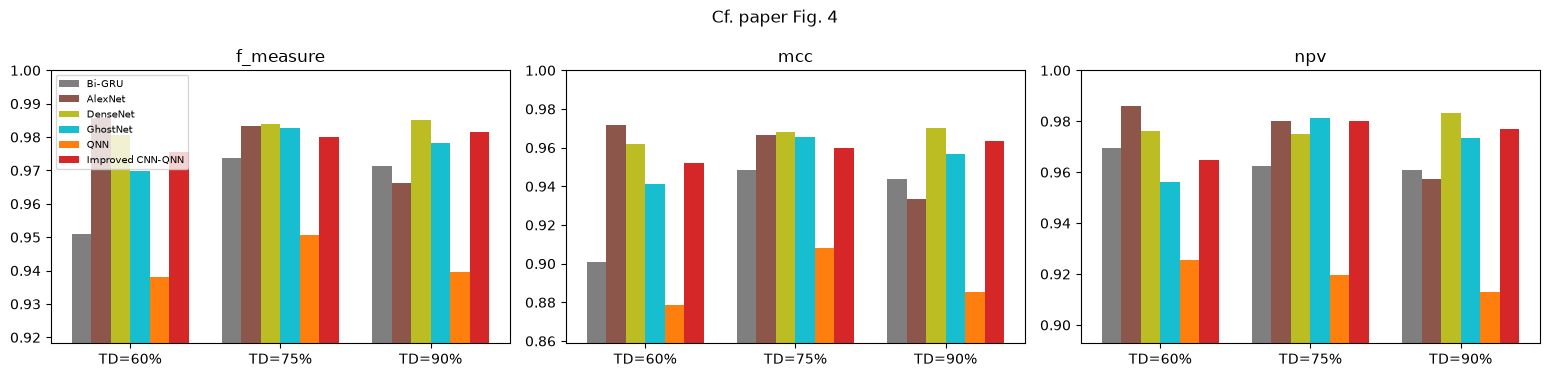

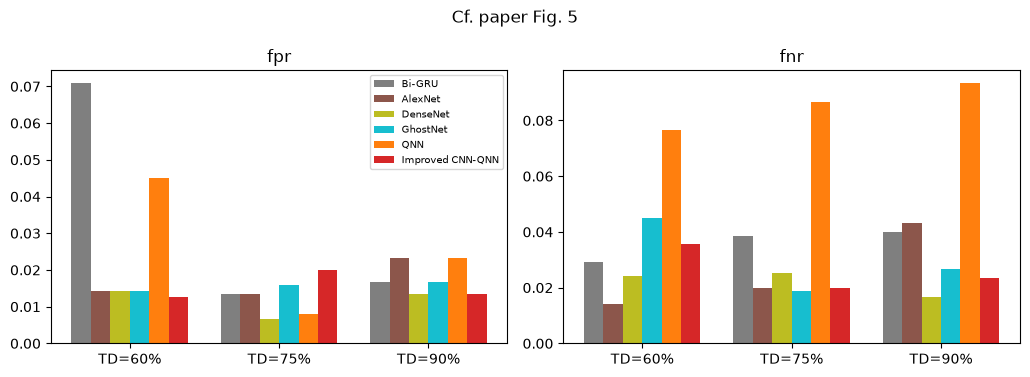

In [23]:
colors = dict(zip(PAPER_ORDER, ["tab:gray", "tab:brown", "tab:olive", "tab:cyan", "tab:orange", "tab:red"]))
def bars(metrics, title):
    fig, axes = plt.subplots(1, len(metrics), figsize=(5.2 * len(metrics), 3.8))
    for ax, m in zip(np.atleast_1d(axes), metrics):
        w = 0.13
        for i, name in enumerate(PAPER_ORDER):
            vals = [RES[(name, td, SEEDS[0])][m] for td in TDS]
            ax.bar(np.arange(len(TDS)) + (i - 2.5) * w, vals, w, color=colors[name], label=name)
        ax.set_xticks(range(len(TDS))); ax.set_xticklabels([f"TD={t}%" for t in TDS]); ax.set_title(m)
        lo = min(RES[(n, td, SEEDS[0])][m] for n in PAPER_ORDER for td in TDS)
        if m not in ("fpr", "fnr"): ax.set_ylim(max(0, lo - 0.02), 1.0)
    np.atleast_1d(axes)[0].legend(fontsize=7)
    fig.suptitle(title); plt.tight_layout(); plt.show()
bars(["specificity", "sensitivity", "accuracy", "precision"], "Cf. paper Fig. 3")
bars(["f_measure", "mcc", "npv"], "Cf. paper Fig. 4")
bars(["fpr", "fnr"], "Cf. paper Fig. 5")

Cf. paper Table I (statistics of accuracy over the 5 runs: TD in [60, 75, 90], seeds [42, 43, 44] at TD=90)


,Bi-GRU,AlexNet,DenseNet,GhostNet,QNN,Improved CNN-QNN
Min,0.950000,0.966667,0.980833,0.970417,0.939167,0.975833
Mean,0.965800,0.982500,0.985300,0.982283,0.948033,0.982500
SD,0.011903,0.008199,0.003023,0.009754,0.010511,0.004773
Median,0.971667,0.985833,0.985000,0.980000,0.941667,0.981667
Max,0.980000,0.990000,0.990000,1.000000,0.966667,0.990000


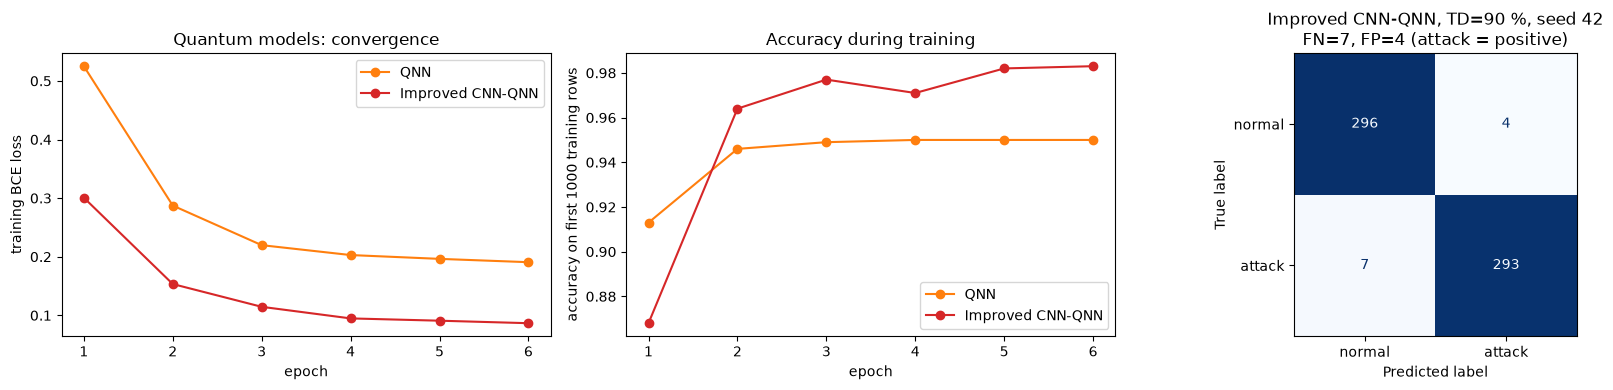

best detector by accuracy in this run: DenseNet


In [24]:
# Table I: statistics of the accuracy over all (TD, seed) runs of a model
stat = {}
for name in PAPER_ORDER:
    v = np.array([RES[(name, td, s)]["accuracy"] for (td, s) in RUNS])
    stat[name] = dict(Min=v.min(), Mean=v.mean(), SD=v.std(), Median=np.median(v), Max=v.max())
TABLE1 = pd.DataFrame(stat).T.round(6)
print(f"Cf. paper Table I (statistics of accuracy over the {len(RUNS)} runs: TD in {TDS}, seeds {SEEDS} at TD={MAIN_TD})")
display(TABLE1.T)

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for name in ["QNN", "Improved CNN-QNN"]:
    h = np.array(HIST[(name, MAIN_TD, SEEDS[0])]); ep = range(1, len(h) + 1)
    axes[0].plot(ep, h[:, 0], "o-", label=name, color=colors[name]); axes[1].plot(ep, h[:, 1], "o-", label=name, color=colors[name])
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("training BCE loss"); axes[0].set_title("Quantum models: convergence"); axes[0].legend()
axes[1].set_xlabel("epoch"); axes[1].set_ylabel(f"accuracy on first {PROBE} training rows"); axes[1].set_title("Accuracy during training"); axes[1].legend()
best = max(PAPER_ORDER, key=lambda n: RES[(n, MAIN_TD, SEEDS[0])]["accuracy"])
ConfusionMatrixDisplay.from_predictions(prepare(MAIN_TD, SEEDS[0])["yte"], PRED[("Improved CNN-QNN", MAIN_TD, SEEDS[0])],
                                        display_labels=["normal", "attack"], ax=axes[2], colorbar=False, cmap="Blues")
r = RES[("Improved CNN-QNN", MAIN_TD, SEEDS[0])]
axes[2].set_title(f"Improved CNN-QNN, TD={MAIN_TD} %, seed {SEEDS[0]}\nFN={r['fn']}, FP={r['fp']} (attack = positive)")
plt.tight_layout(); plt.show()
print("best detector by accuracy in this run:", best)

## 8. Ablations: what do the W-HHSM-BN layer and the quantum circuit contribute?

The paper credits the improvement to the W-HHSM-BN layer integrated with the QNN. Two cheap checks at TD = 90 % (first
seed): (a) the same improved CNN with a **classical linear head** instead of the quantum circuit; (b) the improved CNN-QNN
with plain **batch normalisation** instead of W-HHSM-BN (quantum run, full mode only). The Random Forest on all features is the
classical reference.

In [25]:
td, seed = MAIN_TD, SEEDS[0]
train_net("CNN + classical head", lambda n: CNNClassicalHead(n, True), td, seed, EPOCHS_Q, "all")
if ABLATION_QUANTUM:
    train_net("CNN-QNN (plain BN)", lambda n: make_improved(n, seed, whhsm=False), td, seed, EPOCHS_Q, "all")
keys = ["Improved CNN-QNN", "CNN + classical head"] + (["CNN-QNN (plain BN)"] if ABLATION_QUANTUM else []) + ["QNN", "Random Forest [all features]"]
abl = pd.DataFrame({k: RES[(k, td, seed)] for k in keys}).T[["accuracy", "f_measure", "mcc", "fpr", "fnr", "time_s", "params"]]
print(f"Ablation at TD={td} %, seed {seed} (test set)")
display(abl.round(4))

    CNN + classical head TD=90 seed=42 epoch  1/6 loss 0.3531 probe-acc 0.9540 (11 s)


    CNN + classical head TD=90 seed=42 epoch  3/6 loss 0.2039 probe-acc 0.9680 (36 s)


    CNN + classical head TD=90 seed=42 epoch  6/6 loss 0.1268 probe-acc 0.9850 (69 s)


    CNN-QNN (plain BN) TD=90 seed=42 epoch  1/6 loss 0.2305 probe-acc 0.9730 (32 s)


    CNN-QNN (plain BN) TD=90 seed=42 epoch  3/6 loss 0.0865 probe-acc 0.9870 (93 s)


    CNN-QNN (plain BN) TD=90 seed=42 epoch  6/6 loss 0.0721 probe-acc 0.9890 (181 s)


Ablation at TD=90 %, seed 42 (test set)


,accuracy,f_measure,mcc,fpr,fnr,time_s,params
Improved CNN-QNN,0.9817,0.9816,0.9634,0.0133,0.0233,128.8619,2622.0
CNN + classical head,0.9750,0.9747,0.9503,0.0133,0.0367,72.8996,2573.0
CNN-QNN (plain BN),0.9800,0.9799,0.9601,0.0133,0.0267,192.1876,2622.0
QNN,0.9417,0.9396,0.8855,0.0233,0.0933,37.3274,56.0
Random Forest [all features],0.9967,0.9967,0.9933,0.0033,0.0033,1.9993,-1.0


## 9. Blowfish for data security

Stage 2 of the paper encrypts the records that the detector considers clean. Blowfish (Schneier, 1993) is a 64-bit block
Feistel cipher with a variable key (32 to 448 bits), 16 rounds, an 18-entry P-array and four 256-entry S-boxes of 32-bit
words, all initialised with the **hexadecimal digits of the fractional part of pi** and then mixed with the key by encrypting
an all-zero block 521 times. We implement it from scratch in pure Python (no crypto library), compute the 1,042
initial words from pi with integer arithmetic (Machin's formula), and prove the implementation with the published test
vectors before using it. Records are serialised as CSV text and encrypted in CBC mode with PKCS#7 padding (**CHOICE**: the
paper names no mode).

In [26]:
M32 = 0xFFFFFFFF
def _pi_words(n_words):
    # fractional hexadecimal digits of pi as 32-bit words (integer Machin: pi = 16 atan(1/5) - 4 atan(1/239))
    bits = 32 * n_words + 64
    def atan_inv(x):
        one = 1 << bits; term = one // x; s = term; x2 = x * x; n = 1; sign = -1
        while term:
            term //= x2; n += 2; s += sign * (term // n); sign = -sign
        return s
    pi = 16 * atan_inv(5) - 4 * atan_inv(239)
    frac = (pi - (3 << bits)) >> 64
    return [(frac >> (32 * (n_words - 1 - i))) & M32 for i in range(n_words)]

PI = _pi_words(18 + 4 * 256)
assert PI[0] == 0x243F6A88 and PI[18] == 0xD1310BA6 and PI[-1] == 0x3AC372E6, "pi constants wrong"   # known first/last words
print("computed %d words from pi; P[0] = %08X, S0[0] = %08X, last S-box word = %08X" % (len(PI), PI[0], PI[18], PI[-1]))

class Blowfish:
    def __init__(self, key: bytes):
        assert 4 <= len(key) <= 56, "Blowfish keys are 32 to 448 bits"
        self.P = PI[:18]; self.S = [PI[18 + 256 * i: 18 + 256 * (i + 1)] for i in range(4)]
        for i in range(18):                                              # XOR the cyclic key into the P-array
            k = 0
            for j in range(4): k = (k << 8) | key[(4 * i + j) % len(key)]
            self.P[i] ^= k
        l = r = 0
        for i in range(0, 18, 2):                                        # key expansion: 521 encryptions of the evolving block
            l, r = self._enc(l, r); self.P[i], self.P[i + 1] = l, r
        for box in self.S:
            for i in range(0, 256, 2):
                l, r = self._enc(l, r); box[i], box[i + 1] = l, r
    def _f(self, x):
        S = self.S                                                       # Eq. (4) of the paper
        return ((((S[0][x >> 24] + S[1][(x >> 16) & 255]) & M32) ^ S[2][(x >> 8) & 255]) + S[3][x & 255]) & M32
    def _enc(self, l, r):
        P = self.P
        for i in range(16):
            l ^= P[i]; r ^= self._f(l); l, r = r, l
        l, r = r, l; r ^= P[16]; l ^= P[17]
        return l, r
    def _dec(self, l, r):
        P = self.P
        for i in range(17, 1, -1):
            l ^= P[i]; r ^= self._f(l); l, r = r, l
        l, r = r, l; r ^= P[1]; l ^= P[0]
        return l, r
    def encrypt_block(self, b: bytes) -> bytes:
        l, r = int.from_bytes(b[:4], "big"), int.from_bytes(b[4:], "big"); l, r = self._enc(l, r)
        return l.to_bytes(4, "big") + r.to_bytes(4, "big")
    def decrypt_block(self, b: bytes) -> bytes:
        l, r = int.from_bytes(b[:4], "big"), int.from_bytes(b[4:], "big"); l, r = self._dec(l, r)
        return l.to_bytes(4, "big") + r.to_bytes(4, "big")
    def encrypt_cbc(self, data: bytes, iv: bytes) -> bytes:
        pad = 8 - len(data) % 8; data += bytes([pad]) * pad; out = []; prev = iv
        for i in range(0, len(data), 8):
            prev = self.encrypt_block(bytes(a ^ b for a, b in zip(data[i:i + 8], prev))); out.append(prev)
        return b"".join(out)
    def decrypt_cbc(self, data: bytes, iv: bytes) -> bytes:
        out = []; prev = iv
        for i in range(0, len(data), 8):
            blk = data[i:i + 8]; out.append(bytes(a ^ b for a, b in zip(self.decrypt_block(blk), prev))); prev = blk
        plain = b"".join(out); return plain[:-plain[-1]]

# published ECB test vectors (Eric Young's set / Schneier's Blowfish page): key, plaintext -> ciphertext
VECTORS = [("0000000000000000", "0000000000000000", "4EF997456198DD78"),
           ("FFFFFFFFFFFFFFFF", "FFFFFFFFFFFFFFFF", "51866FD5B85ECB8A"),
           ("3000000000000000", "1000000000000001", "7D856F9A613063F2"),
           ("1111111111111111", "1111111111111111", "2466DD878B963C9D"),
           ("0123456789ABCDEF", "1111111111111111", "61F9C3802281B096")]
for k, p, c in VECTORS:
    got = Blowfish(bytes.fromhex(k)).encrypt_block(bytes.fromhex(p)).hex().upper()
    print(f"key {k} plain {p} -> {got}  expected {c}  {'OK' if got == c else 'MISMATCH'}")
    assert got == c
    assert Blowfish(bytes.fromhex(k)).decrypt_block(bytes.fromhex(c)).hex().upper() == p
print("all published test vectors reproduced; decryption inverts encryption")

computed 1042 words from pi; P[0] = 243F6A88, S0[0] = D1310BA6, last S-box word = 3AC372E6
key 0000000000000000 plain 0000000000000000 -> 4EF997456198DD78  expected 4EF997456198DD78  OK
key FFFFFFFFFFFFFFFF plain FFFFFFFFFFFFFFFF -> 51866FD5B85ECB8A  expected 51866FD5B85ECB8A  OK
key 3000000000000000 plain 1000000000000001 -> 7D856F9A613063F2  expected 7D856F9A613063F2  OK
key 1111111111111111 plain 1111111111111111 -> 2466DD878B963C9D  expected 2466DD878B963C9D  OK


key 0123456789ABCDEF plain 1111111111111111 -> 61F9C3802281B096  expected 61F9C3802281B096  OK
all published test vectors reproduced; decryption inverts encryption


In [27]:
# Stage 2 of the paper: records that the detector declares clean (predicted normal) are encrypted; the others are withheld.
d = prepare(MAIN_TD, SEEDS[0]); pred = PRED[("Improved CNN-QNN", MAIN_TD, SEEDS[0])]
te = d["te"]; clean = te[pred == 0]; withheld = te[pred == 1]
print(f"improved CNN-QNN on the test split: {len(clean)} connections judged clean (of which {int((clean.binary == 1).sum())} are in fact attacks), "
      f"{len(withheld)} withheld as attacks")
sel = clean.head(N_BLOWFISH)
records = [",".join(str(v) for v in row).encode() for row in sel[COLUMNS].itertuples(index=False)]
ivs = [rng.integers(0, 256, 8, dtype=np.uint8).tobytes() for _ in records]               # fresh random IV per record (seeded)
key = hashlib.sha256(b"demo key, do not use").digest()[:16]                                # 128-bit demo key (CHOICE)
bf = Blowfish(key)
t0 = time.time(); cts = [bf.encrypt_cbc(r, iv) for r, iv in zip(records, ivs)]; t_enc = time.time() - t0
t0 = time.time(); pts = [bf.decrypt_cbc(c, iv) for c, iv in zip(cts, ivs)]; t_dec = time.time() - t0
assert pts == records, "round trip failed"
print(f"{len(records)} real flow records ({np.mean([len(r) for r in records]):.0f} bytes each): encrypt {t_enc*1000/len(records):.2f} ms/record, "
      f"decrypt {t_dec*1000/len(records):.2f} ms/record (pure Python); round trip exact")
print("example plaintext :", records[0][:70].decode(), "...")
print("example ciphertext:", cts[0][:24].hex(), "...")

improved CNN-QNN on the test split: 303 connections judged clean (of which 7 are in fact attacks), 297 withheld as attacks


303 real flow records (128 bytes each): encrypt 1.09 ms/record, decrypt 1.04 ms/record (pure Python); round trip exact
example plaintext : 0,tcp,http,SF,195,3267,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,15,15,0.0,0.0,0 ...
example ciphertext: 7d74e65e4beb4b08e9000535c8a19da2435e12a59205e3f0 ...


In [28]:
# Cipher sanity beyond the test vectors (NOT the paper's Table II): key-setup time per key length and the avalanche effect
# (flip one plaintext bit -> about half of the 64 ciphertext bits should change).
rows = []
for bits in [32, 64, 128, 256, 448]:
    k = rng.integers(0, 256, bits // 8, dtype=np.uint8).tobytes()
    t0 = time.time(); c = Blowfish(k); t_setup = time.time() - t0
    flips = []
    for _ in range(200):
        blk = rng.integers(0, 256, 8, dtype=np.uint8).tobytes(); j = int(rng.integers(0, 64))
        blk2 = bytearray(blk); blk2[j // 8] ^= 1 << (j % 8)
        a, b = c.encrypt_block(blk), c.encrypt_block(bytes(blk2))
        flips.append(bin(int.from_bytes(a, "big") ^ int.from_bytes(b, "big")).count("1"))
    rows.append(dict(key_bits=bits, key_setup_ms=round(t_setup * 1000, 2), mean_changed_bits_of_64=round(float(np.mean(flips)), 2)))
display(pd.DataFrame(rows))
print("Paper Table II lists key sizes 16, 32, 64, 128 (units not stated); Blowfish accepts 32 to 448 bits, so the 16 cannot be bits.")

,key_bits,key_setup_ms,mean_changed_bits_of_64
0,32,30.58,32.30
1,64,22.39,31.91
2,128,31.61,31.86
3,256,24.70,32.23
4,448,24.63,31.89


Paper Table II lists key sizes 16, 32, 64, 128 (units not stated); Blowfish accepts 32 to 448 bits, so the 16 cannot be bits.


## 10. Side by side with the paper

Verdict rule: a numeric claim is *reproduced* when the notebook's value is within 0.02 of the paper's (accuracy, MCC, FPR),
otherwise *not reached* (we are lower; for FPR/FNR: higher) or *exceeded* (we are better), with the gap shown. Qualitative
claims are checked on the means. Table II (attack values of Blowfish, RSA, AES, Fernet) *cannot be checked*: the measure is
not defined and no code is given.

In [29]:
PAPER_ACC  = {"Improved CNN-QNN": 0.97583, "Bi-GRU": 0.9069444, "AlexNet": 0.91527, "DenseNet": 0.915277, "GhostNet": 0.92138, "QNN": 0.948333}
PAPER_FPR  = {"Improved CNN-QNN": 0.0143, "Bi-GRU": 0.05568, "AlexNet": 0.050683, "DenseNet": 0.050683, "GhostNet": 0.047015, "QNN": 0.030843}
PAPER_MCC  = {"Improved CNN-QNN": 0.9130, "Bi-GRU": 0.665223, "AlexNet": 0.695203, "DenseNet": 0.69520, "GhostNet": 0.717188, "QNN": 0.814124}
PAPER_T1   = {"Bi-GRU": [0.856597, 0.883652, 0.018819, 0.885532, 0.906944], "AlexNet": [0.860486, 0.888791, 0.020967, 0.889699, 0.915278],
              "DenseNet": [0.865347, 0.890006, 0.017954, 0.889699, 0.915278], "GhostNet": [0.865069, 0.891834, 0.021305, 0.89044, 0.921389],
              "QNN": [0.909931, 0.929682, 0.014824, 0.930231, 0.948333], "Improved CNN-QNN": [0.939931, 0.957147, 0.013521, 0.956412, 0.975833]}

def verdict(paper, ours, higher_is_better=True, tol=0.02):
    gap = ours - paper
    if abs(gap) <= tol: return "reproduced", gap
    better = gap > 0 if higher_is_better else gap < 0
    return ("exceeded" if better else "not reached"), gap

claims = []
mu = lambda n, m: mean_over_seeds(n, MAIN_TD, m)[0]
for name in PAPER_ORDER:
    for label, table, metric, hib in [("accuracy", PAPER_ACC, "accuracy", True), ("MCC", PAPER_MCC, "mcc", True), ("FPR", PAPER_FPR, "fpr", False)]:
        v, gap = verdict(table[name], mu(name, metric), hib)
        claims.append(dict(claim=f"{name}: {label} at TD=90 %", paper=table[name], notebook=round(mu(name, metric), 4), gap=round(gap, 4), verdict=v))
for name in ["Improved CNN-QNN", "QNN"]:
    for i, st in enumerate(["Min", "Mean", "SD", "Median", "Max"]):
        v, gap = verdict(PAPER_T1[name][i], float(TABLE1.loc[name, st]), True, 0.02 if st != "SD" else 0.01)
        if st == "SD": v = "reproduced" if abs(gap) <= 0.01 else "differs"
        claims.append(dict(claim=f"Table I, {name}: accuracy {st}", paper=PAPER_T1[name][i], notebook=round(float(TABLE1.loc[name, st]), 4), gap=round(gap, 4), verdict=v))
acc = {n: mu(n, "accuracy") for n in PAPER_ORDER}
classical = ["Bi-GRU", "AlexNet", "DenseNet", "GhostNet"]
claims += [
    dict(claim="Improved CNN-QNN has the highest accuracy of the six", paper="yes", notebook=max(acc, key=acc.get), gap="",
         verdict="reproduced" if max(acc, key=acc.get) == "Improved CNN-QNN" else "not reached"),
    dict(claim="Improved CNN-QNN > plain QNN (accuracy)", paper="0.9758 vs 0.9483", notebook=f"{acc['Improved CNN-QNN']:.4f} vs {acc['QNN']:.4f}",
         gap=round(acc["Improved CNN-QNN"] - acc["QNN"], 4), verdict="reproduced" if acc["Improved CNN-QNN"] > acc["QNN"] else "not reached"),
    dict(claim="Plain QNN > all four classical networks (accuracy)", paper="yes", notebook=f"QNN {acc['QNN']:.4f} vs best classical {max(acc[c] for c in classical):.4f}",
         gap=round(acc["QNN"] - max(acc[c] for c in classical), 4), verdict="reproduced" if acc["QNN"] > max(acc[c] for c in classical) else "not reached"),
    dict(claim="Bi-GRU is the weakest of the six", paper="yes", notebook=min(acc, key=acc.get), gap="",
         verdict="reproduced" if min(acc, key=acc.get) == "Bi-GRU" else "not reached"),
    dict(claim="Improved CNN-QNN has the lowest FPR of the six", paper="0.0143", notebook=min(PAPER_ORDER, key=lambda n: mu(n, 'fpr')), gap="",
         verdict="reproduced" if min(PAPER_ORDER, key=lambda n: mu(n, 'fpr')) == "Improved CNN-QNN" else "not reached"),
    dict(claim="Improved CNN-QNN beats a Random Forest on the same data", paper="not tested in the paper", notebook=f"{acc['Improved CNN-QNN']:.4f} vs {mean_over_seeds('Random Forest [all features]', MAIN_TD, 'accuracy')[0]:.4f}",
         gap=round(acc["Improved CNN-QNN"] - mean_over_seeds("Random Forest [all features]", MAIN_TD, "accuracy")[0], 4), verdict="not reached" if acc["Improved CNN-QNN"] < mean_over_seeds("Random Forest [all features]", MAIN_TD, "accuracy")[0] else "reproduced"),
    dict(claim="Blowfish: correct cipher, round trip of records judged clean", paper="Sec. V", notebook="5/5 test vectors, exact round trip", gap="", verdict="reproduced (implementation checked)"),
    dict(claim="Table II: Blowfish attack values (CCA, CPA, FIA, KPA) lower than RSA, AES, Fernet", paper="0.110, 0.060, 0.068, 0.044 at key size 128", notebook="no definition / no code", gap="", verdict="cannot be checked"),
]
CLAIMS = pd.DataFrame(claims)
pd.set_option("display.max_colwidth", 80)
display(CLAIMS)
print(CLAIMS["verdict"].str.split(" ").str[0].value_counts().to_string())

,claim,paper,notebook,gap,verdict
0,Bi-GRU: accuracy at TD=90 %,0.906944,0.9683,0.0614,exceeded
1,Bi-GRU: MCC at TD=90 %,0.665223,0.9369,0.2717,exceeded
2,Bi-GRU: FPR at TD=90 %,0.05568,0.0211,-0.0346,exceeded
3,AlexNet: accuracy at TD=90 %,0.91527,0.9811,0.0658,exceeded
4,AlexNet: MCC at TD=90 %,0.695203,0.9623,0.2671,exceeded
5,AlexNet: FPR at TD=90 %,0.050683,0.0133,-0.0373,exceeded
6,DenseNet: accuracy at TD=90 %,0.915277,0.9872,0.0719,exceeded
7,DenseNet: MCC at TD=90 %,0.6952,0.9745,0.2793,exceeded
8,DenseNet: FPR at TD=90 %,0.050683,0.0156,-0.0351,exceeded
9,GhostNet: accuracy at TD=90 %,0.92138,0.9861,0.0647,exceeded


verdict
exceeded      18
reproduced    13
not            4
cannot         1


### Are the paper's own numbers consistent?

Accuracy, FPR and MCC of one model are tied together by the class balance of the test set. Given a model's accuracy `A`,
FPR `f` and MCC `m` from the paper (Sec. VI.B), we search the positive-class share `p` of the test set for which
`FNR = (1 - A - (1 - p) f) / p` reproduces the reported MCC. If the paper's six models share one test set, the six `p`
should agree. If instead `p` comes out near 0.5, the MCC values are inconsistent with the accuracies.

In [30]:
def mcc_from(p, acc, fpr):
    fnr = (1 - acc - (1 - p) * fpr) / p
    if not (0 <= fnr <= 1): return np.nan
    tp, fn, fp, tn = p * (1 - fnr), p * fnr, (1 - p) * fpr, (1 - p) * (1 - fpr)
    den = math.sqrt((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn))
    return (tp * tn - fp * fn) / den if den else np.nan

rows = []
grid = np.linspace(0.02, 0.98, 961)
for name in PAPER_ORDER:
    vals = np.array([mcc_from(p, PAPER_ACC[name], PAPER_FPR[name]) for p in grid])
    err = np.nan_to_num(np.abs(vals - PAPER_MCC[name]), nan=9.0)
    roots = [round(float(grid[i]), 3) for i in range(1, len(grid) - 1) if err[i] < 0.003 and err[i] <= err[i - 1] and err[i] <= err[i + 1]]
    p5 = mcc_from(0.5, PAPER_ACC[name], PAPER_FPR[name])
    rows.append(dict(model=name, paper_acc=PAPER_ACC[name], paper_fpr=PAPER_FPR[name], paper_mcc=PAPER_MCC[name],
                     mcc_implied_if_balanced=round(p5, 4), positive_shares_that_fit_the_paper_mcc=roots))
display(pd.DataFrame(rows))

              model  paper_acc  paper_fpr  paper_mcc  mcc_implied_if_balanced positive_shares_that_fit_the_paper_mcc
0            Bi-GRU   0.906944   0.055680   0.665223                   0.8162                         [0.167, 0.896]
1           AlexNet   0.915270   0.050683   0.695203                   0.8325                          [0.167, 0.89]
2          DenseNet   0.915277   0.050683   0.695200                   0.8325                          [0.167, 0.89]
3          GhostNet   0.921380   0.047015   0.717188                   0.8444                         [0.167, 0.886]
4               QNN   0.948333   0.030843   0.814124                   0.8974                         [0.167, 0.867]
5  Improved CNN-QNN   0.975830   0.014300   0.913000                   0.9518                         [0.167, 0.849]

## 11. Reading the paper critically

Everything below refers to numbers computed above: the verdict table of Section 10 (13 checks "reproduced", 18 "exceeded", 4 "not reached", 1 "cannot be checked"), the three-seed table of Section 7, the ablation of Section 8 and the consistency check of the paper's own metrics.

**The headline number is reproduced, the story around it is not.** At TD = 90 % the improved CNN-QNN reaches 0.9856 +- 0.0034 accuracy (paper 0.9758), FPR 0.0078 (paper 0.0143), and the plain QNN 0.9494 +- 0.0122 (paper 0.9483). Both quantum models land where the paper says, and "improved CNN-QNN > plain QNN" holds by 3.6 points. But the paper's other claims depend on weak comparators. Our Bi-GRU, AlexNet, DenseNet and GhostNet, a few thousand parameters each and trained for 8 epochs, reach 0.968 to 0.987, i.e. 6 to 7 points above the paper's 0.907 to 0.921. As a result the improved CNN-QNN is **not** the best detector here (DenseNet 0.9872, GhostNet 0.9861, AlexNet 0.9811 are on par within the seed-to-seed standard deviation of 0.2 to 1.0 points), the plain QNN is **not** better than the classical networks (it is the weakest of the six, 0.9494 against 0.968 to 0.987), and Bi-GRU is not the weakest. The paper's ranking "QNN > classical deep nets" is an artefact of how strong the classical nets were made, not a property of quantum circuits.

**The quantum circuit adds nothing that we can measure.** The ablation of Section 8 (one seed, 600 test connections, standard error of an accuracy near 0.98 is about 0.55 points) gives 0.9817 for the improved CNN-QNN, 0.9750 for the same CNN with a plain linear head and 0.9800 with ordinary batch normalisation instead of the reconstructed W-HHSM-BN layer. All three differences are about one standard error or less, so neither the quantum head nor the new layer is shown to matter; the CNN front end does the work (the 2,566 classical parameters against 56 in the circuit). On the same six PCA angles a Random Forest scores 0.9883 and an RBF-SVM 0.9683, both above the 56-parameter QNN (0.9494), and a Random Forest on all features scores 0.9967 in 2 s, 1.1 points above the proposed model that needs about 2 minutes on a CPU simulator. The paper does not include a Random Forest or SVM baseline, which would have been the first thing to check on KDD Cup 99.

**The paper's own metrics are internally inconsistent unless the test set is imbalanced.** For a balanced test set, accuracy 0.9758 and FPR 0.0143 imply MCC 0.952, not the reported 0.913, and for Bi-GRU 0.8162 against 0.665. The consistency check above finds that all six models fit the same positive-class share, 0.167 = 1/6 (each also has a second root between 0.85 and 0.90, which differs from model to model and is therefore not a common test set). So the paper's test set most probably holds about one attack in six, while the text says nothing about class balance and our balanced sample therefore does not recreate the paper's setting. With 1/6 attacks our improved CNN-QNN would score 0.1667 x 0.9789 + 0.8333 x 0.9922 = 0.990 accuracy, i.e. the conclusion does not change, but MCC and precision would be lower than in our balanced test.

**What a 600-connection test set can and cannot say.** Our test set at TD = 90 % has 600 connections (the paper's presumably 3,600), so a single run has a standard error of about 0.5 points. Differences of 1 point between DenseNet, GhostNet, AlexNet and the improved CNN-QNN, which decide the "best model" claim, are inside the noise of 3 seeds. The KDD Cup 99 10 % file is also an easy benchmark after de-duplication (the single DoS flood `neptune` is 90 % of all attacks and DoS in total 94 %), so near-ceiling scores for almost every model are expected and say little about detecting new attacks; no zero-day or cross-dataset test is run in the paper or here.

**Training artefacts we met.** In a first run DenseNet and GhostNet sometimes collapsed to a single class at test time (accuracy 0.50) because the batch-norm running statistics lag behind the weights after a few hundred Adam steps; re-estimating them on the training set after training (Section 6) fixed it. The "probe-acc" column in the training logs is computed before that recalibration and therefore fluctuates (0.48 to 0.99) for the batch-norm networks; the test numbers are computed after it. The W-HHSM-BN layer is our reconstruction of garbled equations, so the layer's real behaviour in the paper is untested here.

**Blowfish and Table II.** Our pure-Python implementation reproduces five published test vectors, round-trips the 303 records the detector judged clean (7 of which were actually attacks, a 2.3 % leak of attacks into the encrypted channel) and shows an avalanche effect of 31.9 to 32.3 changed bits of 64. This shows that Blowfish works as a cipher; it does not show anything about the paper's Table II, whose CCA / CPA / FIA / KPA "attack values" are not defined, are not in any standard cryptographic security notion that yields a number between 0 and 1, and cannot be recomputed. Key sizes 16 to 128 are not valid in bits (Blowfish needs 32 to 448), RSA, AES and Fernet are not comparable primitives (asymmetric vs symmetric vs an authenticated wrapper around AES), and the paper does not name a mode of operation. The claim that Blowfish "guarantees" confidentiality and integrity is also wrong as stated: plain Blowfish gives no integrity at all, and its 64-bit block is considered too small for large volumes of data (Sweet32).

**Overall.** What is reproduced: the pipeline is implementable, the improved CNN-QNN scores about 0.98 on KDD Cup 99 and beats the plain QNN. What is not: the ranking against classical networks, any evidence that the quantum part or the W-HHSM-BN layer contributes, and the security comparison of Table II. Status: partially reproduced.

## 12. Exercises

Each exercise changes the code of an earlier cell. Rerun that cell and everything after it, or set `FAST_MODE = True` first
to see the direction of the effect in a few minutes.

1. **Number of qubits.** Set `N_QUBITS = 4`, then `8`. *Observe:* does the accuracy of the plain QNN and of the improved CNN-QNN
   move with the qubit count, and how does the run time scale (each qubit doubles the state vector)?
2. **Depth of the variational block.** Set `Q_LAYERS = 1`, `3`, `6`. *Observe:* does the improved CNN-QNN depend on the
   circuit at all, compared with the "CNN + classical head" ablation of Section 8?
3. **The W-HHSM-BN reconstruction.** Change `w_max`, `w_min` in `WHHSMBN`, or drop the softmax branch of Eq. (1). Compare with
   the plain-BN ablation (`ABLATION_QUANTUM = True`). *Observe:* is there any setting where the layer helps measurably, given
   the seed-to-seed spread of the table in Section 7?
4. **A harder, honest split.** The 10 % KDD file is dominated by two DoS floods. Restrict `raw` to the non-DoS families
   (`raw = raw[raw.family != "DoS"]`) before Section 2, or train on 90 % and test on `corrected` (the competition's test set, which
   contains attacks not in the training data; `fetch_kddcup99(percent10=False)` has the full file). *Observe:* which of the six
   detectors degrades most, and does any of the paper's ranking survive?
5. **Encryption mode.** Replace CBC by ECB in Section 9 and encrypt two identical records. *Observe:* what does an eavesdropper
   see, and why is the paper's statement "Blowfish guarantees protected data transfer" incomplete without a mode and a key
   exchange?